In [19]:
df = spark.sql("""
    SELECT
        Sysid,
        LOGIN_ID,
        LOGDATE,                 -- date column
        LOGDATETIME,             -- timestamp if needed for time-of-day analysis
        ACTION,
        DETAIL,
        LAST,
        FIRST,
        MIDDLE,
        CARD_NUM,
        ID_NUM,
        FACILITY,
        DESCRIP,
        SHORT_DESCRIP,

        -- ---------
        -- Derived Variables
        -- ---------

        -- Flag rows where ACTION indicates printing
        CASE 
            WHEN LOWER(ACTION) LIKE '%print%' THEN 1 
            ELSE 0 
        END AS PrintFlag,

        -- UP vs CWC grouping
        CASE 
            WHEN DESCRIP = 'University Park' THEN 'UP'
            ELSE 'CWC'
        END AS RegionGroup

    FROM Cleansed_IDMS_Auditlog
    WHERE 
        LOGDATE >= '2025-01-01'
        AND LOWER(ACTION) LIKE '%print%'    -- PrintFlag filter early for efficiency
        AND CDFFILE NOT IN (
            'PROX','Vendor','TEMPCARD','STUDENT MASCOT','TIME','BACK-LAUNDRY','AC-BACK',
            'ContingentAccessCard','LAUNDRY','TIMEANDATTENDANCE','TempCard','VENDOR',
            'ACCESSCARD','FOODSERVICES'
        )
""")

df.createOrReplaceTempView("print_df")

df.printSchema()
df.show(20)


StatementMeta(, 64169b29-2ac5-4013-bd3c-530b109c9137, 23, Finished, Available, Finished)

root
 |-- Sysid: string (nullable = true)
 |-- LOGIN_ID: string (nullable = true)
 |-- LOGDATE: string (nullable = true)
 |-- LOGDATETIME: double (nullable = true)
 |-- ACTION: string (nullable = true)
 |-- DETAIL: string (nullable = true)
 |-- LAST: string (nullable = true)
 |-- FIRST: string (nullable = true)
 |-- MIDDLE: string (nullable = true)
 |-- CARD_NUM: string (nullable = true)
 |-- ID_NUM: string (nullable = true)
 |-- FACILITY: string (nullable = true)
 |-- DESCRIP: string (nullable = true)
 |-- SHORT_DESCRIP: string (nullable = true)
 |-- PrintFlag: integer (nullable = false)
 |-- RegionGroup: string (nullable = false)

+------+-----------+--------------------+-----------+-----------+-------+---------+---------+---------+----------------+---------+--------+--------------------+---------------+---------+-----------+
| Sysid|   LOGIN_ID|             LOGDATE|LOGDATETIME|     ACTION| DETAIL|     LAST|    FIRST|   MIDDLE|        CARD_NUM|   ID_NUM|FACILITY|             DESCRIP|

In [20]:
import pandas as pd

pdf = df.toPandas()
pdf['LOGDATE'] = pd.to_datetime(pdf['LOGDATE'], format='mixed', errors='coerce')



StatementMeta(, 64169b29-2ac5-4013-bd3c-530b109c9137, 24, Finished, Available, Finished)

In [21]:
daily = pdf.groupby(['LOGDATE', 'RegionGroup']).size().reset_index(name='PrintCount')


StatementMeta(, 64169b29-2ac5-4013-bd3c-530b109c9137, 25, Finished, Available, Finished)

StatementMeta(, 64169b29-2ac5-4013-bd3c-530b109c9137, 26, Finished, Available, Finished)

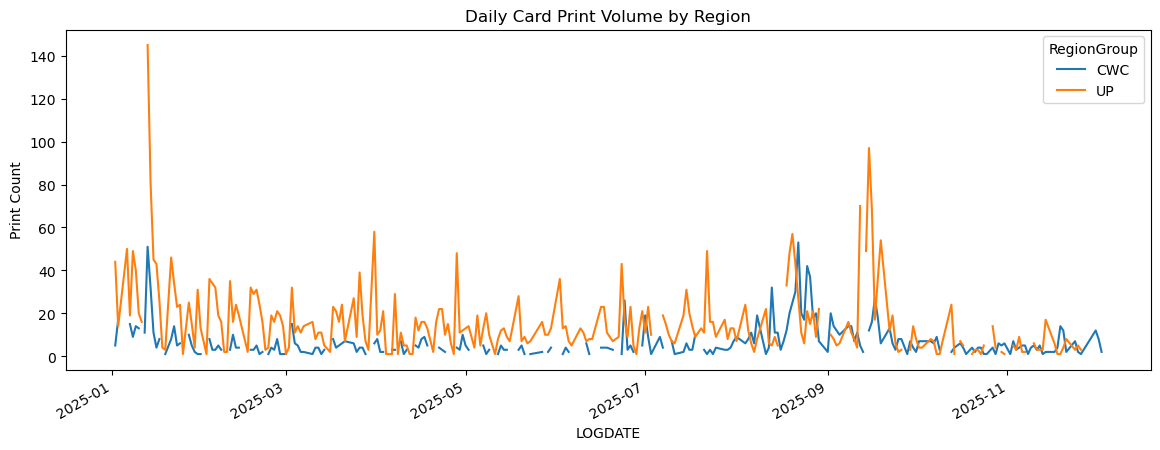

In [22]:
import matplotlib.pyplot as plt

daily.pivot(index='LOGDATE', columns='RegionGroup', values='PrintCount').plot(figsize=(14,5))
plt.title("Daily Card Print Volume by Region")
plt.ylabel("Print Count")
plt.show()


In [23]:
mean_val = daily['PrintCount'].mean()
var_val = daily['PrintCount'].var()

dispersion_ratio = var_val / mean_val
dispersion_ratio


StatementMeta(, 64169b29-2ac5-4013-bd3c-530b109c9137, 27, Finished, Available, Finished)

16.775035799131683

**Note:** This dispersion ratio shows you don't want to use a Poisson or Binomial model since the variability is considered quite high (>10).

StatementMeta(, 64169b29-2ac5-4013-bd3c-530b109c9137, 28, Finished, Available, Finished)

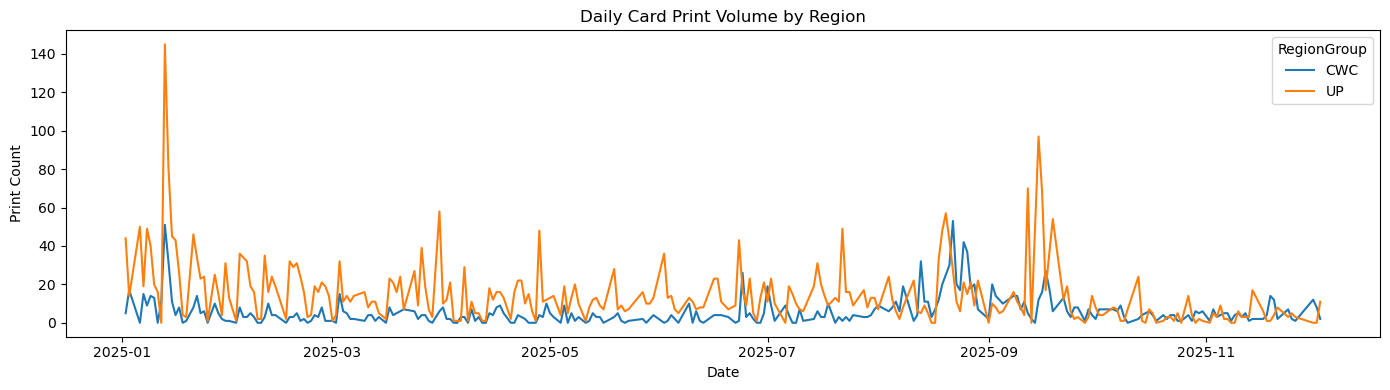

In [24]:
# ==============================================
# 3. Daily Counts by RegionGroup (UP vs CWC)
# ==============================================

daily_region = (
    pdf.groupby(["LOGDATE", "RegionGroup"])
       .size()
       .reset_index(name="PrintCount")
)

# Pivot for plotting
daily_region_pivot = daily_region.pivot(
    index="LOGDATE",
    columns="RegionGroup",
    values="PrintCount"
).fillna(0)

# ==============================================
# 4. Plot Daily Trends by RegionGroup (UP vs CWC)
# ==============================================

plt.figure()
for col in daily_region_pivot.columns:
    plt.plot(daily_region_pivot.index, daily_region_pivot[col], label=col)

plt.title("Daily Card Print Volume by Region")
plt.xlabel("Date")
plt.ylabel("Print Count")
plt.legend(title="RegionGroup")
plt.tight_layout()
plt.show()

In [25]:
# ==============================================
# 5. Daily Counts by DESCRIP (Location)
# ==============================================

daily_desc = (
    pdf.groupby(["LOGDATE", "DESCRIP"])
       .size()
       .reset_index(name="PrintCount")
)

# Optional: see which locations you have
print("DESCRIP values:")
print(sorted(daily_desc["DESCRIP"].unique()))

StatementMeta(, 64169b29-2ac5-4013-bd3c-530b109c9137, 29, Finished, Available, Finished)

DESCRIP values:
['Carlisle Campus', 'Penn State Abington', 'Penn State Altoona', 'Penn State Beaver', 'Penn State Berks', 'Penn State Brandywine', 'Penn State Erie', 'Penn State Fayette', 'Penn State Greater Allegheny', 'Penn State Harrisburg', 'Penn State Hazleton', 'Penn State Lehigh Valley', 'Penn State Mont Alto', 'Penn State New Kensington', 'Penn State Schuylkill', 'Penn State Shenango', 'Penn State Wilkes-Barre', 'Penn State York', 'University Park']


StatementMeta(, 64169b29-2ac5-4013-bd3c-530b109c9137, 30, Finished, Available, Finished)

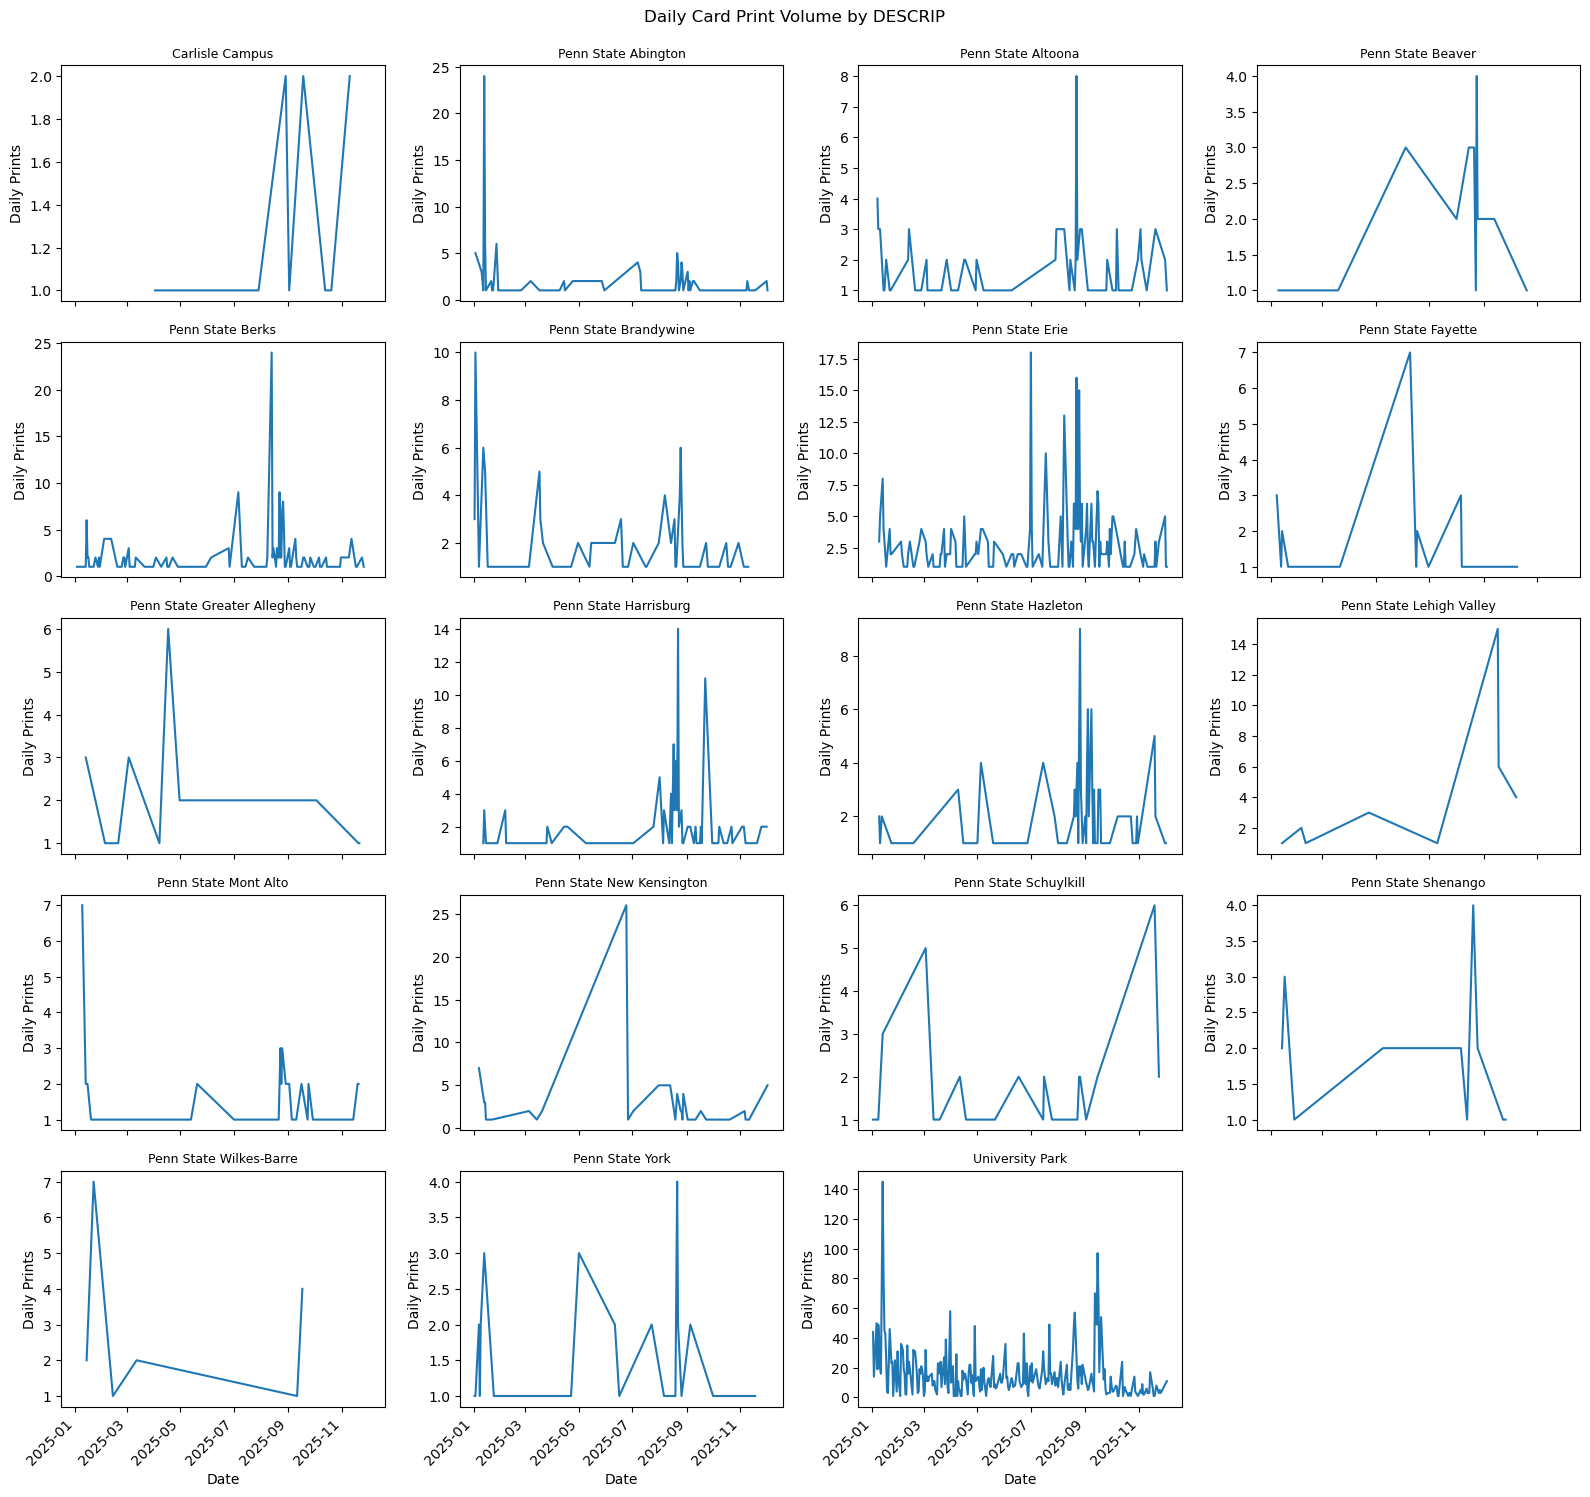

In [26]:
import numpy as np
import matplotlib.pyplot as plt
import math

# ==============================================
# 6. Small Multiples: DAILY trends by DESCRIP
# ==============================================

# Prepare list of locations
locations = sorted(daily_desc["DESCRIP"].unique())
n_locations = len(locations)

# Layout for small multiples
n_cols = 4  # change if you prefer different width
n_rows = math.ceil(n_locations / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(4*n_cols, 3*n_rows), sharex=True)
axes = np.atleast_1d(axes).ravel()  # flatten in case of single row

for i, loc in enumerate(locations):
    ax = axes[i]
    sub = daily_desc[daily_desc["DESCRIP"] == loc].sort_values("LOGDATE")
    ax.plot(sub["LOGDATE"], sub["PrintCount"])
    ax.set_title(loc, fontsize=9)
    ax.set_ylabel("Daily Prints")
    # Only bottom row gets x-labels
    if i // n_cols == n_rows - 1:
        ax.set_xlabel("Date")
        for label in ax.get_xticklabels():
            label.set_rotation(45)
            label.set_ha("right")

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle("Daily Card Print Volume by DESCRIP", y=0.995)
plt.tight_layout()
plt.show()


StatementMeta(, 64169b29-2ac5-4013-bd3c-530b109c9137, 31, Finished, Available, Finished)

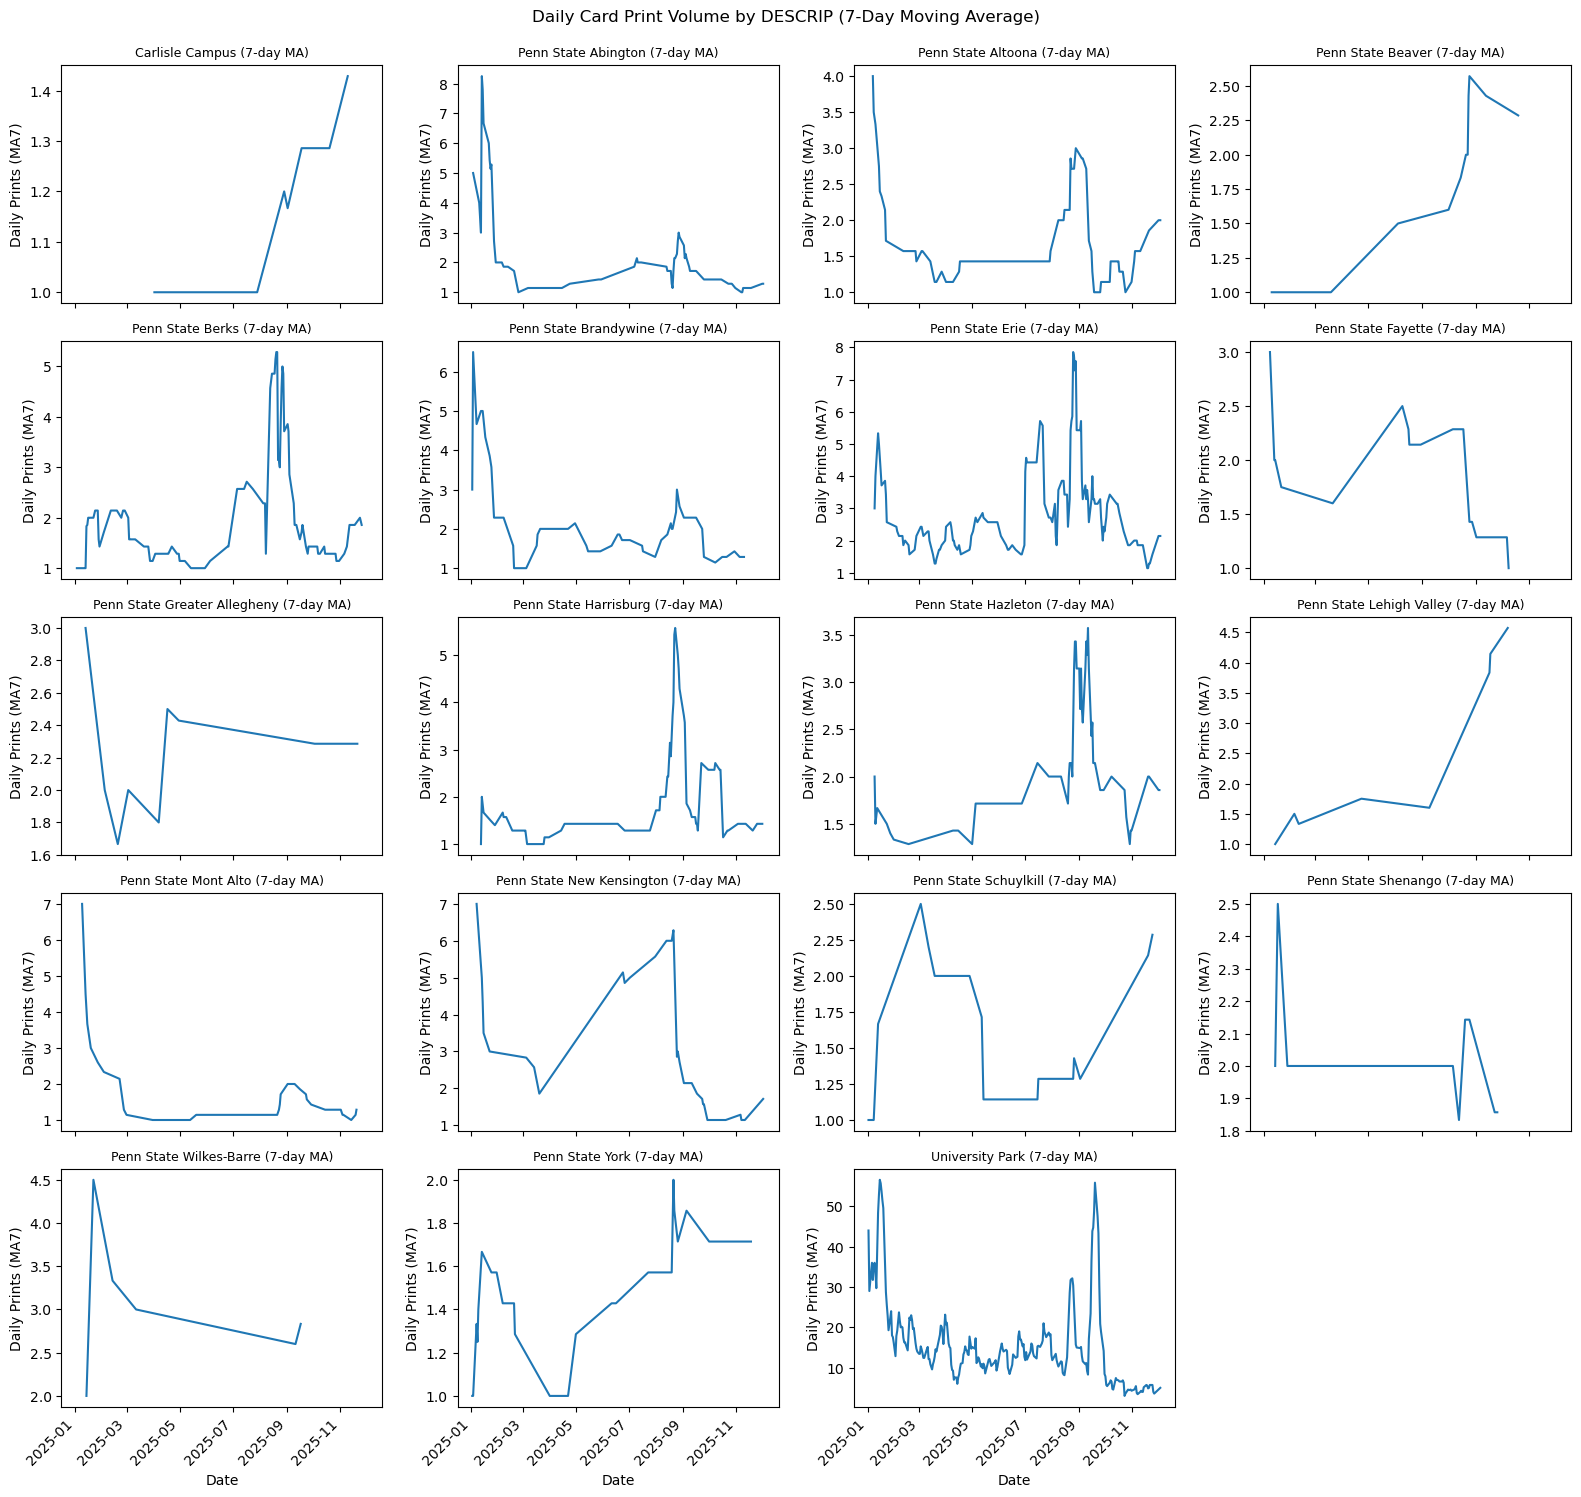

In [27]:
# ==============================================
# 7. Optional: 7-Day Moving Average by DESCRIP (smoother small multiples)
# ==============================================

daily_desc_ma = daily_desc.copy()
daily_desc_ma["MA7"] = (
    daily_desc_ma
    .groupby("DESCRIP")["PrintCount"]
    .transform(lambda x: x.sort_index().rolling(7, min_periods=1).mean())
)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(4*n_cols, 3*n_rows), sharex=True)
axes = np.atleast_1d(axes).ravel()

for i, loc in enumerate(locations):
    ax = axes[i]
    sub = daily_desc_ma[daily_desc_ma["DESCRIP"] == loc].sort_values("LOGDATE")
    ax.plot(sub["LOGDATE"], sub["MA7"])
    ax.set_title(loc + " (7-day MA)", fontsize=9)
    ax.set_ylabel("Daily Prints (MA7)")
    if i // n_cols == n_rows - 1:
        ax.set_xlabel("Date")
        for label in ax.get_xticklabels():
            label.set_rotation(45)
            label.set_ha("right")

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle("Daily Card Print Volume by DESCRIP (7-Day Moving Average)", y=0.995)
plt.tight_layout()
plt.show()


StatementMeta(, 64169b29-2ac5-4013-bd3c-530b109c9137, 32, Finished, Available, Finished)

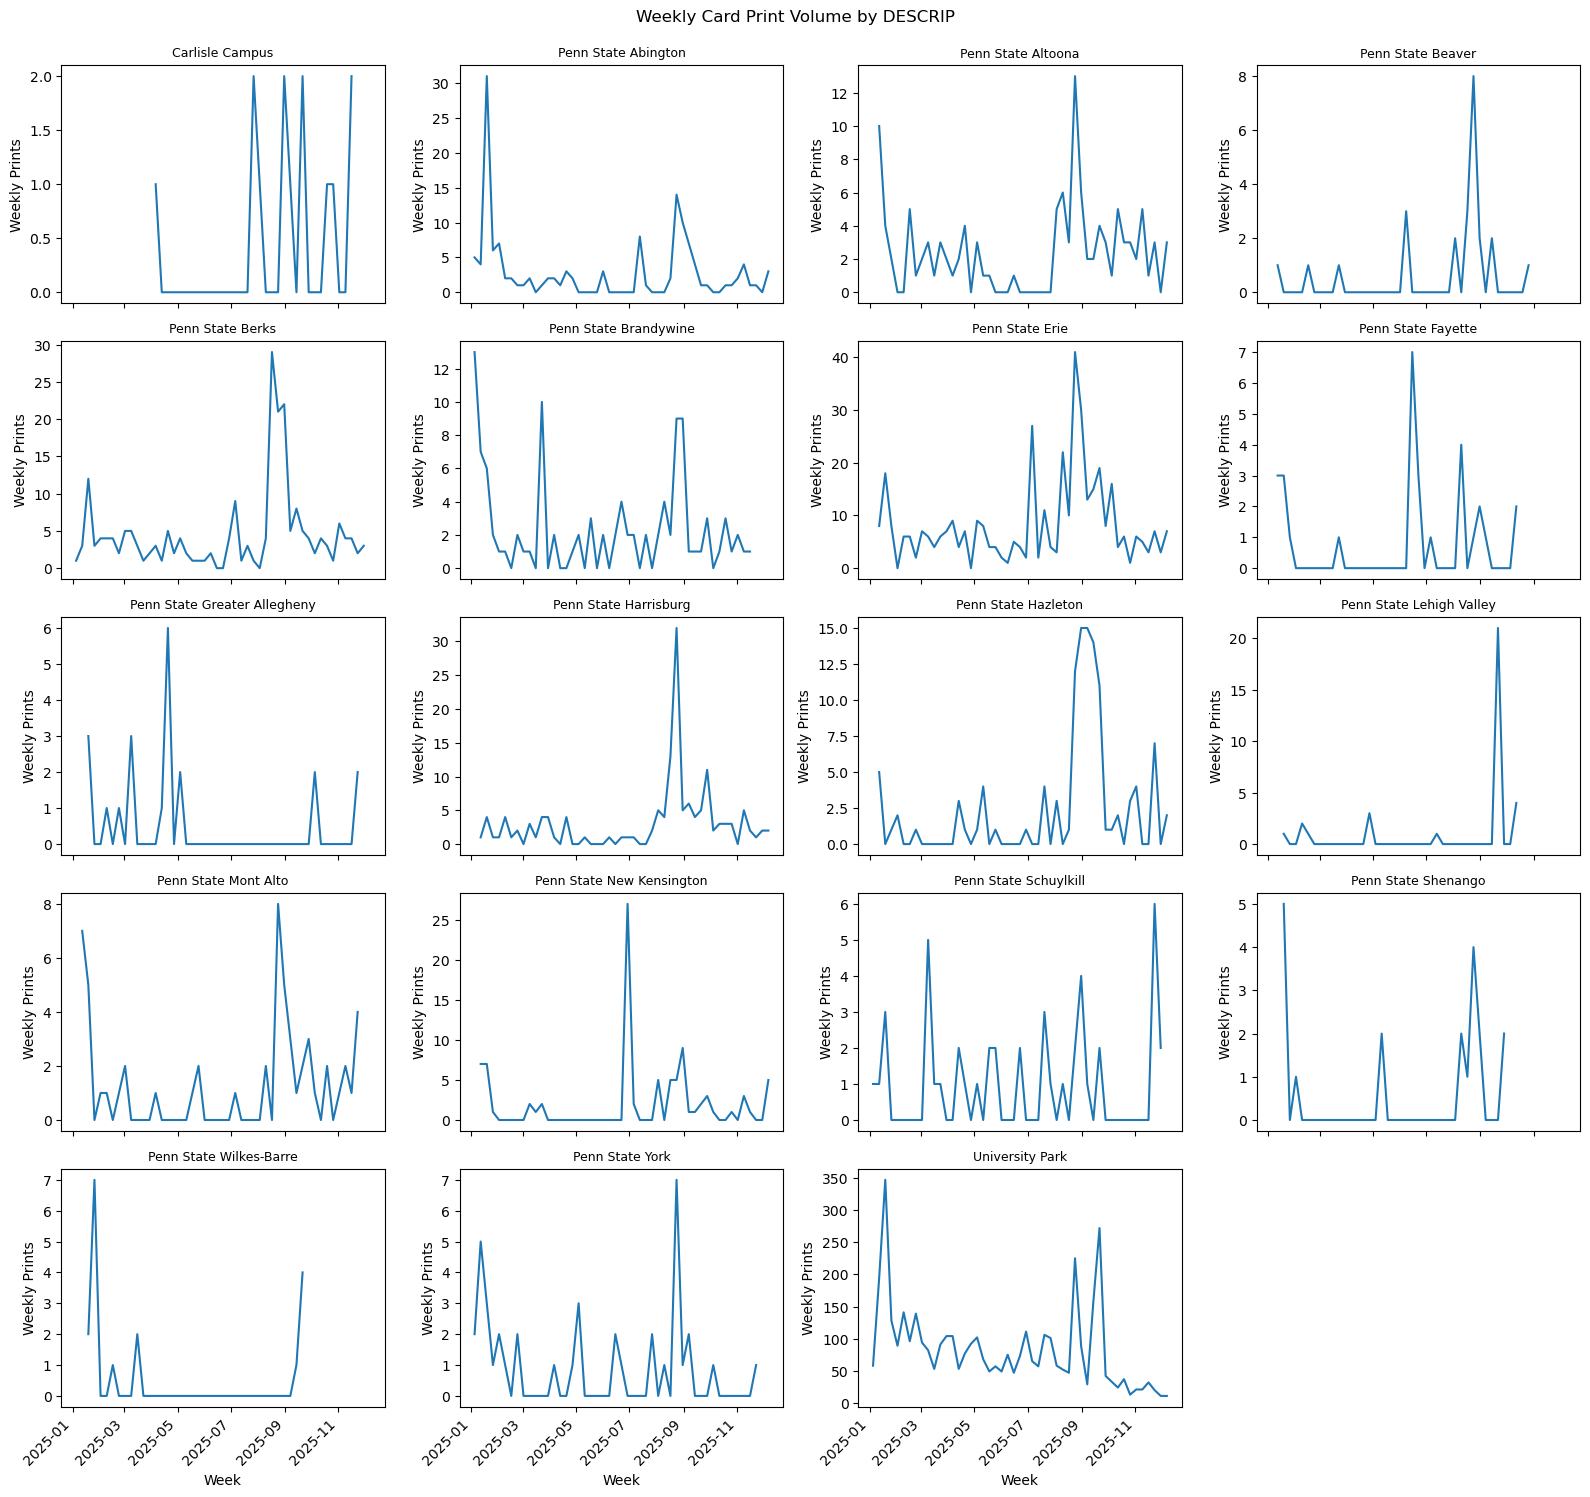

In [28]:
# ==============================================
# 8. Weekly Counts by DESCRIP (for smoother trends)
# ==============================================

weekly_desc = (
    daily_desc
    .set_index("LOGDATE")
    .groupby("DESCRIP")["PrintCount"]
    .resample("W-SUN")  # weekly ending Sunday; adjust if you prefer
    .sum()
    .reset_index()
)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(4*n_cols, 3*n_rows), sharex=True)
axes = np.atleast_1d(axes).ravel()

for i, loc in enumerate(locations):
    ax = axes[i]
    sub = weekly_desc[weekly_desc["DESCRIP"] == loc].sort_values("LOGDATE")
    ax.plot(sub["LOGDATE"], sub["PrintCount"])
    ax.set_title(loc, fontsize=9)
    ax.set_ylabel("Weekly Prints")
    if i // n_cols == n_rows - 1:
        ax.set_xlabel("Week")
        for label in ax.get_xticklabels():
            label.set_rotation(45)
            label.set_ha("right")

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle("Weekly Card Print Volume by DESCRIP", y=0.995)
plt.tight_layout()
plt.show()

StatementMeta(, 64169b29-2ac5-4013-bd3c-530b109c9137, 33, Finished, Available, Finished)

     LOGDATE  PrintCount
0 2025-01-02          49
1 2025-01-03          31
2 2025-01-06          50
3 2025-01-07          34
4 2025-01-08          58


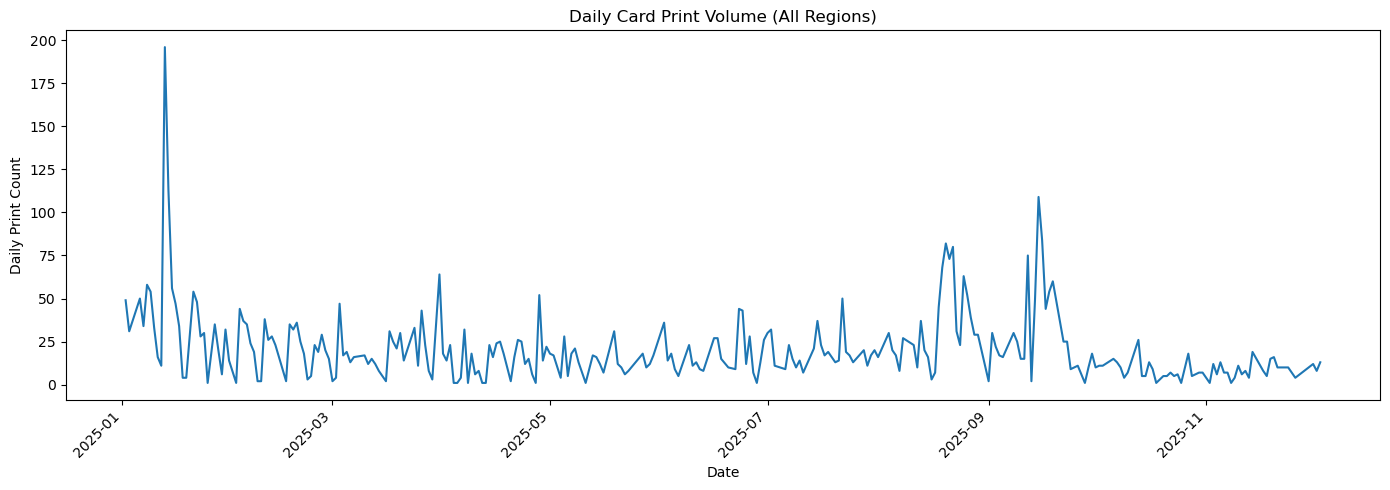

In [29]:
# ================================
# Daily total prints (all regions)
# ================================

# pdf is the Pandas dataframe from earlier with LOGDATE already parsed
daily_total = (
    pdf.groupby("LOGDATE")
       .size()
       .reset_index(name="PrintCount")
       .sort_values("LOGDATE")
)

# Quick sanity check
print(daily_total.head())

# ================================
# Plot: Daily total print volume
# ================================
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(daily_total["LOGDATE"], daily_total["PrintCount"])
plt.title("Daily Card Print Volume (All Regions)")
plt.xlabel("Date")
plt.ylabel("Daily Print Count")

# Optional: rotate date labels
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()


StatementMeta(, 64169b29-2ac5-4013-bd3c-530b109c9137, 34, Finished, Available, Finished)


===== FIVE NUMBER SUMMARY =====
Min    : 1
Q1     : 8.0
Median : 16.0
Q3     : 27.0
Max    : 196

===== SUMMARY STATISTICS =====
Mean:       20.87
Median:     16.00
Mode:       1
Std Dev:    20.85

===== ZERO-PRINT DAYS =====
Zero-print days: 0 out of 274 (0.00% of days)

===== DISTRIBUTION SHAPE =====
Skewness:   3.38  (positive = right tail)
Kurtosis:   20.10  (high = heavy tail / spikes)


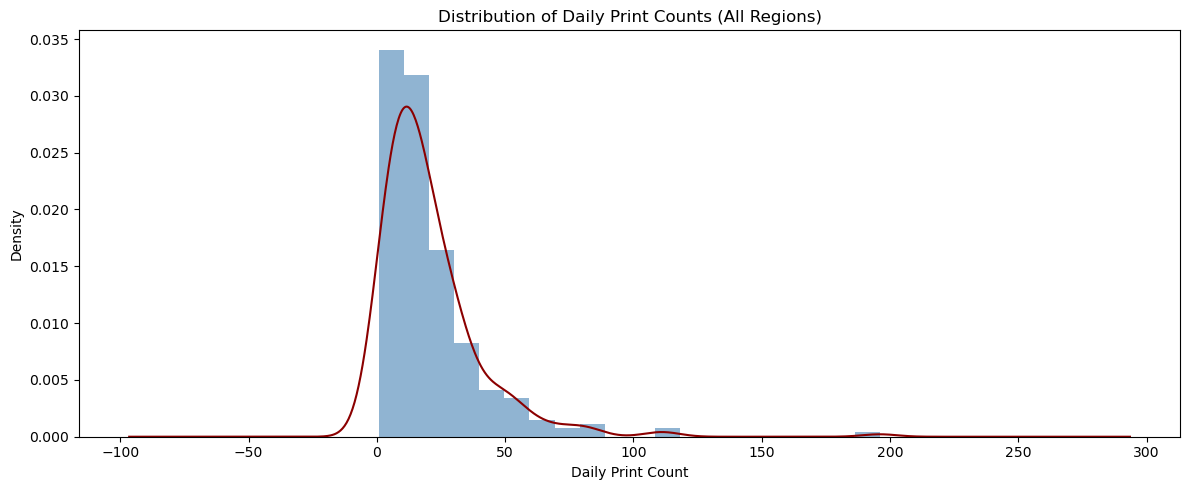


===== SAMPLE OF DAILY TOTALS =====
     LOGDATE  PrintCount
0 2025-01-02          49
1 2025-01-03          31
2 2025-01-06          50
3 2025-01-07          34
4 2025-01-08          58


In [30]:
# ==========================================
# DAILY TOTAL PRINT ANALYSIS (ALL REGIONS)
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# --------------------------------------------------
# 1. Aggregate to daily totals
# --------------------------------------------------
daily_total = (
    pdf.groupby("LOGDATE")
       .size()
       .reset_index(name="PrintCount")
       .sort_values("LOGDATE")
)

# --------------------------------------------------
# 2. Five-number summary
# --------------------------------------------------
five_num = {
    "Min": daily_total["PrintCount"].min(),
    "Q1":  daily_total["PrintCount"].quantile(0.25),
    "Median": daily_total["PrintCount"].median(),
    "Q3": daily_total["PrintCount"].quantile(0.75),
    "Max": daily_total["PrintCount"].max()
}

print("\n===== FIVE NUMBER SUMMARY =====")
for k, v in five_num.items():
    print(f"{k:7}: {v}")

# --------------------------------------------------
# 3. Mean, Median, Mode, Std Dev
# --------------------------------------------------
mean_val = daily_total["PrintCount"].mean()
median_val = daily_total["PrintCount"].median()

# Mode may return multiple values depending on distribution
try:
    mode_val = stats.mode(daily_total["PrintCount"], keepdims=True).mode[0]
except:
    mode_val = "No unique mode"

std_val = daily_total["PrintCount"].std()

print("\n===== SUMMARY STATISTICS =====")
print(f"Mean:       {mean_val:.2f}")
print(f"Median:     {median_val:.2f}")
print(f"Mode:       {mode_val}")
print(f"Std Dev:    {std_val:.2f}")

# --------------------------------------------------
# 4. Frequency of zero-print days
# --------------------------------------------------
zero_days = (daily_total["PrintCount"] == 0).sum()
total_days = len(daily_total)
zero_pct = zero_days / total_days * 100

print("\n===== ZERO-PRINT DAYS =====")
print(f"Zero-print days: {zero_days} out of {total_days} "
      f"({zero_pct:.2f}% of days)")

# --------------------------------------------------
# 5. Distribution overview
# --------------------------------------------------
skew_val = daily_total["PrintCount"].skew()
kurt_val = daily_total["PrintCount"].kurt()

print("\n===== DISTRIBUTION SHAPE =====")
print(f"Skewness:   {skew_val:.2f}  (positive = right tail)")
print(f"Kurtosis:   {kurt_val:.2f}  (high = heavy tail / spikes)")

# --------------------------------------------------
# 6. Histogram + KDE (smoothed density)
# --------------------------------------------------
plt.figure(figsize=(12,5))
plt.hist(daily_total["PrintCount"], bins=20, alpha=0.6, color="steelblue", density=True)
daily_total["PrintCount"].plot(kind="kde", color="darkred")
plt.title("Distribution of Daily Print Counts (All Regions)")
plt.xlabel("Daily Print Count")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 7. Print head of daily totals for reference
# --------------------------------------------------
print("\n===== SAMPLE OF DAILY TOTALS =====")
print(daily_total.head())


StatementMeta(, 64169b29-2ac5-4013-bd3c-530b109c9137, 35, Finished, Available, Finished)

Regions: ['CWC', 'UP']
Date range: 2025-01-02 00:00:00 → 2025-12-03 00:00:00

REGION: CWC

--- FIVE NUMBER SUMMARY ---
Min    : 0.0
Q1     : 0.0
Median : 3.0
Q3     : 6.0
Max    : 53.0

--- SUMMARY STATS ---
Mean:     4.83
Median:   3.00
Mode:     0.0
Std Dev:  7.21

--- ZERO-PRINT DAYS ---
Zero-print days: 102 / 336 (30.36%)

--- DISTRIBUTION SHAPE ---
Skewness: 3.27
Kurtosis: 14.54 (higher = heavier tail)

REGION: UP

--- FIVE NUMBER SUMMARY ---
Min    : 0.0
Q1     : 1.0
Median : 8.0
Q3     : 16.0
Max    : 145.0

--- SUMMARY STATS ---
Mean:     12.19
Median:   8.00
Mode:     0.0
Std Dev:  16.12

--- ZERO-PRINT DAYS ---
Zero-print days: 78 / 336 (23.21%)

--- DISTRIBUTION SHAPE ---
Skewness: 3.16
Kurtosis: 16.84 (higher = heavier tail)


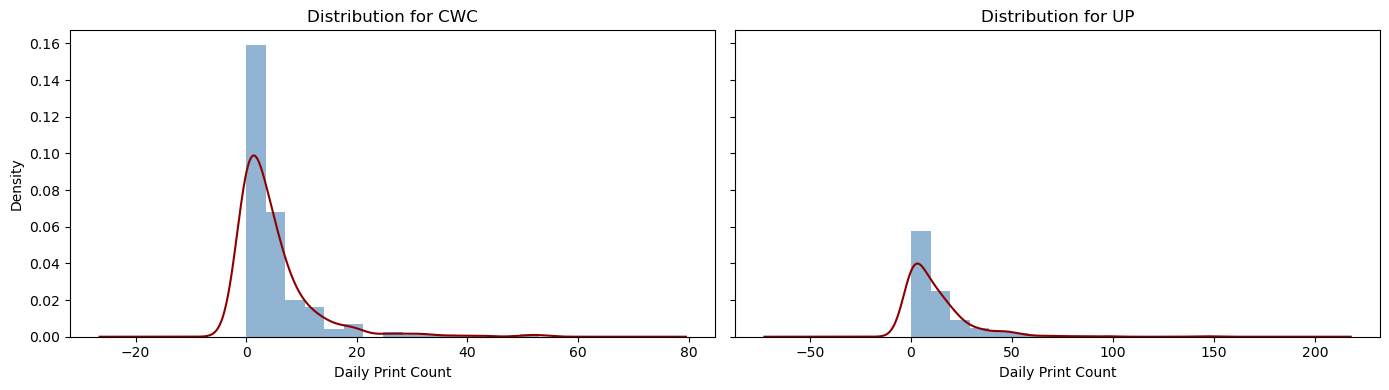

In [31]:
# ==========================================================
# REGIONAL DAILY PRINT STATISTICS (UP vs CWC)
# ==========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# ----------------------------------------------------------
# 1. Aggregate observed counts PER REGION (raw)
# ----------------------------------------------------------
daily_region_raw = (
    pdf.groupby(["LOGDATE", "RegionGroup"])
       .size()
       .reset_index(name="PrintCount")
)

# ----------------------------------------------------------
# 2. Build a COMPLETE date range across the whole dataset
# ----------------------------------------------------------
full_dates = pd.DataFrame({
    "LOGDATE": pd.date_range(
        start=daily_region_raw["LOGDATE"].min(),
        end=daily_region_raw["LOGDATE"].max(),
        freq="D"
    )
})

# ----------------------------------------------------------
# 3. Build a complete region × date grid
# ----------------------------------------------------------
regions = sorted(daily_region_raw["RegionGroup"].unique())

full_grid = (
    full_dates.assign(key=1)
    .merge(pd.DataFrame({"RegionGroup": regions, "key": 1}), on="key")
    .drop(columns="key")
)

# ----------------------------------------------------------
# 4. Merge observed data onto the full grid
# ----------------------------------------------------------
daily_region = (
    full_grid.merge(
        daily_region_raw,
        on=["LOGDATE", "RegionGroup"],
        how="left"
    )
)

# Fill missing with zeros → TRUE zero-print days
daily_region["PrintCount"] = daily_region["PrintCount"].fillna(0)

# Sort for cleanliness
daily_region = daily_region.sort_values(["RegionGroup", "LOGDATE"])

print("Regions:", regions)
print("Date range:", daily_region["LOGDATE"].min(), "→", daily_region["LOGDATE"].max())

# Container for statistics
region_stats = {}

# ----------------------------------------------------------
# 5. Loop through regions and compute statistics
# ----------------------------------------------------------
for reg in regions:
    sub = daily_region[daily_region["RegionGroup"] == reg].copy()
    
    # Five-number summary
    five_num = {
        "Min": sub["PrintCount"].min(),
        "Q1": sub["PrintCount"].quantile(0.25),
        "Median": sub["PrintCount"].median(),
        "Q3": sub["PrintCount"].quantile(0.75),
        "Max": sub["PrintCount"].max()
    }

    # Central tendency
    mean_val   = sub["PrintCount"].mean()
    median_val = sub["PrintCount"].median()
    
    try:
        mode_val = stats.mode(sub["PrintCount"], keepdims=True).mode[0]
    except:
        mode_val = "No unique mode"

    std_val = sub["PrintCount"].std()

    # Zero-print days
    zero_days = (sub["PrintCount"] == 0).sum()
    total_days = len(sub)
    zero_pct = zero_days / total_days * 100

    # Distribution shape
    skew_val = sub["PrintCount"].skew()
    kurt_val = sub["PrintCount"].kurt()

    # Store results
    region_stats[reg] = {
        "five_num": five_num,
        "mean": mean_val,
        "median": median_val,
        "mode": mode_val,
        "std": std_val,
        "zero_days": zero_days,
        "total_days": total_days,
        "zero_pct": zero_pct,
        "skew": skew_val,
        "kurt": kurt_val,
        "data": sub,
    }

# ----------------------------------------------------------
# 6. Print formatted results
# ----------------------------------------------------------
for reg in regions:
    s = region_stats[reg]
    print("\n=======================================")
    print(f"REGION: {reg}")
    print("=======================================")

    print("\n--- FIVE NUMBER SUMMARY ---")
    for k, v in s["five_num"].items():
        print(f"{k:7}: {v}")

    print("\n--- SUMMARY STATS ---")
    print(f"Mean:     {s['mean']:.2f}")
    print(f"Median:   {s['median']:.2f}")
    print(f"Mode:     {s['mode']}")
    print(f"Std Dev:  {s['std']:.2f}")

    print("\n--- ZERO-PRINT DAYS ---")
    print(f"Zero-print days: {s['zero_days']} / {s['total_days']} "
          f"({s['zero_pct']:.2f}%)")

    print("\n--- DISTRIBUTION SHAPE ---")
    print(f"Skewness: {s['skew']:.2f}")
    print(f"Kurtosis: {s['kurt']:.2f} (higher = heavier tail)")

# ----------------------------------------------------------
# 7. Histogram + KDE per region
# ----------------------------------------------------------

fig, axes = plt.subplots(1, len(regions), figsize=(14, 4), sharey=True)

for ax, reg in zip(axes, regions):
    sub = region_stats[reg]["data"]

    ax.hist(sub["PrintCount"], bins=15, density=True, alpha=0.6, color="steelblue")
    sub["PrintCount"].plot(kind="kde", color="darkred", ax=ax)

    ax.set_title(f"Distribution for {reg}")
    ax.set_xlabel("Daily Print Count")
    ax.set_ylabel("Density")

plt.tight_layout()
plt.show()


StatementMeta(, 64169b29-2ac5-4013-bd3c-530b109c9137, 36, Finished, Available, Finished)


ZERO-PRINT DAYS BY WEEKDAY — CWC

Weekday
Monday        5
Tuesday       4
Wednesday     2
Thursday      3
Friday        9
Saturday     41
Sunday       38
dtype: int64

ZERO-PRINT DAYS BY WEEKDAY — UP

Weekday
Monday        4
Tuesday       1
Wednesday     2
Thursday      2
Friday        3
Saturday     36
Sunday       30
dtype: int64


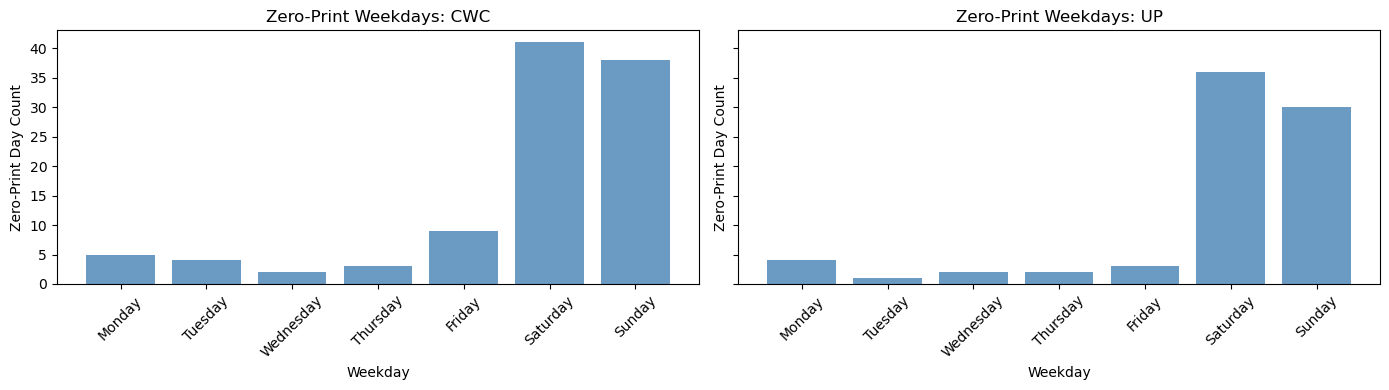

In [32]:
# ==========================================================
# ZERO-PRINT WEEKDAY ANALYSIS (UP vs CWC)
# ==========================================================

# Ensure weekday is available (0 = Monday, 6 = Sunday)
daily_region["Weekday"] = daily_region["LOGDATE"].dt.day_name()

weekday_stats = {}

for reg in regions:
    sub = daily_region[daily_region["RegionGroup"] == reg]

    # Identify zero days
    zero_sub = sub[sub["PrintCount"] == 0]

    # Count zero days per weekday
    zero_by_weekday = (
        zero_sub.groupby("Weekday")
                .size()
                .reindex(
                    ["Monday", "Tuesday", "Wednesday", "Thursday", 
                     "Friday", "Saturday", "Sunday"], fill_value=0
                )
    )

    weekday_stats[reg] = zero_by_weekday

# ----------------------------------------------------------
# Print weekday zero-day stats
# ----------------------------------------------------------
for reg in regions:
    print("\n=======================================")
    print(f"ZERO-PRINT DAYS BY WEEKDAY — {reg}")
    print("=======================================\n")
    print(weekday_stats[reg])

# ----------------------------------------------------------
# Bar chart comparing zero-print weekdays
# ----------------------------------------------------------

fig, axes = plt.subplots(1, len(regions), figsize=(14, 4), sharey=True)

for ax, reg in zip(axes, regions):
    data = weekday_stats[reg]

    ax.bar(data.index, data.values, color="steelblue", alpha=0.8)
    ax.set_title(f"Zero-Print Weekdays: {reg}")
    ax.set_xlabel("Weekday")
    ax.set_ylabel("Zero-Print Day Count")
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


StatementMeta(, 64169b29-2ac5-4013-bd3c-530b109c9137, 37, Finished, Available, Finished)

/home/trusted-service-user/cluster-env/clonedenv/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/home/trusted-service-user/cluster-env/clonedenv/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)



--- TEST SET ACCURACY ---
RMSE: 6.98
MAE:  5.79
MAPE: 215868146726.75%


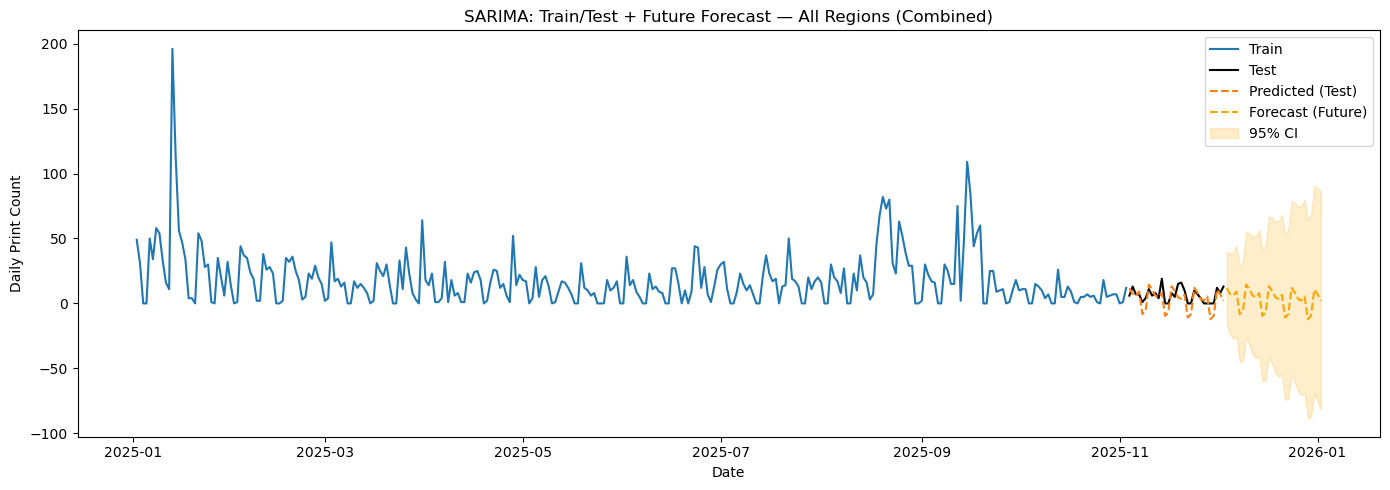

/home/trusted-service-user/cluster-env/clonedenv/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/home/trusted-service-user/cluster-env/clonedenv/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)



--- TEST SET ACCURACY ---
RMSE: 3.49
MAE:  2.78
MAPE: 41584876053.64%


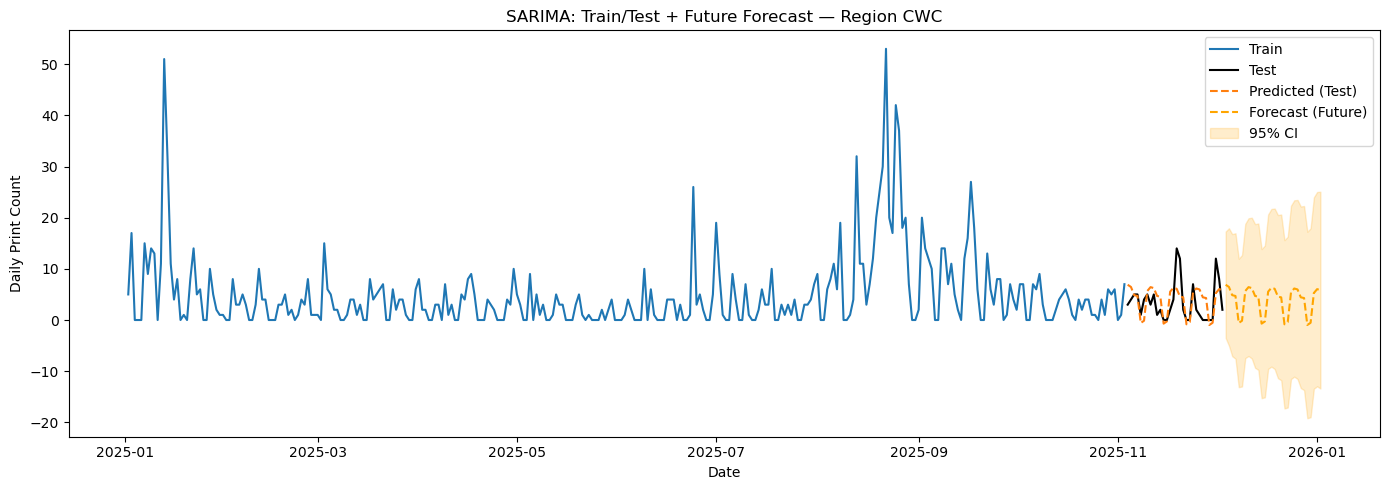

/home/trusted-service-user/cluster-env/clonedenv/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/home/trusted-service-user/cluster-env/clonedenv/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)



--- TEST SET ACCURACY ---
RMSE: 5.94
MAE:  5.04
MAPE: 236162240036.11%


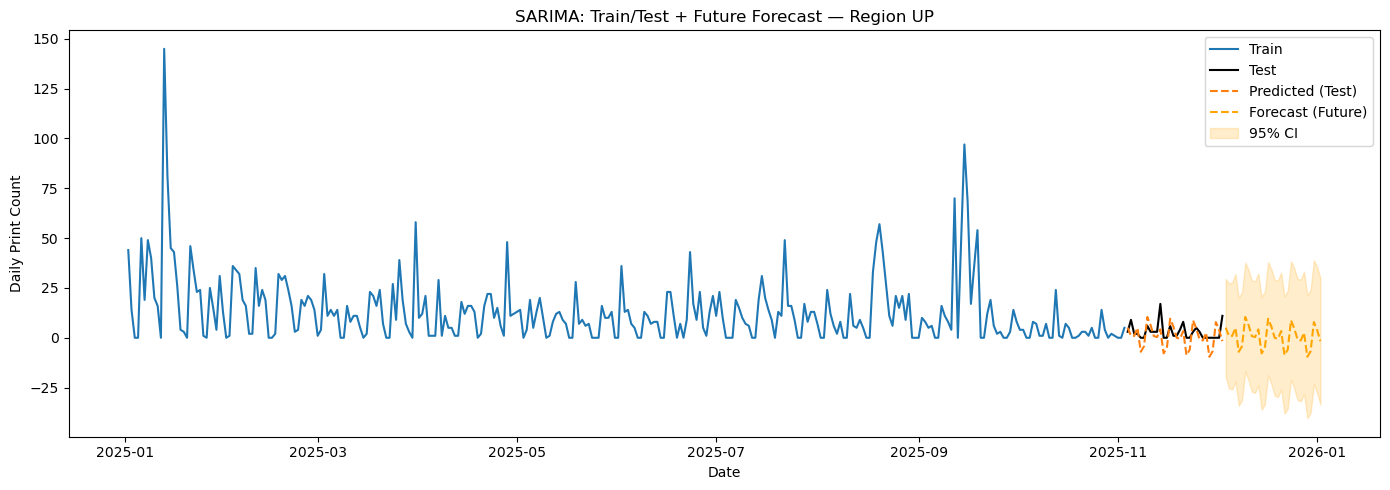

/home/trusted-service-user/cluster-env/clonedenv/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/home/trusted-service-user/cluster-env/clonedenv/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)



--- TEST SET ACCURACY ---
RMSE: 5.94
MAE:  5.04
MAPE: 236162240036.11%


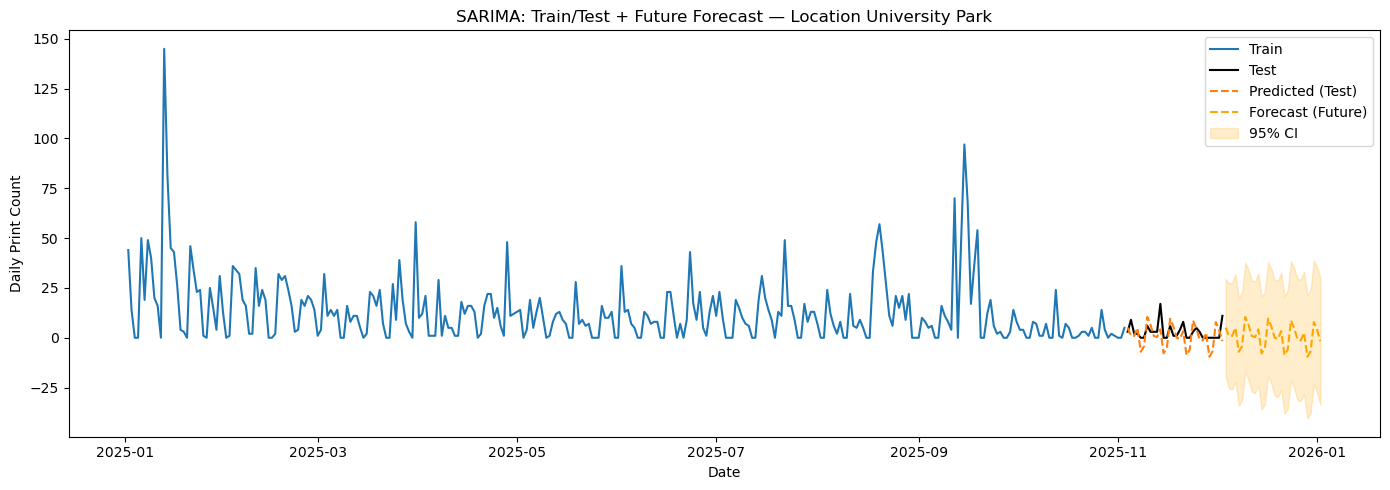

/home/trusted-service-user/cluster-env/clonedenv/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/home/trusted-service-user/cluster-env/clonedenv/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)



--- TEST SET ACCURACY ---
RMSE: 1.05
MAE:  0.78
MAPE: 42529982790.50%


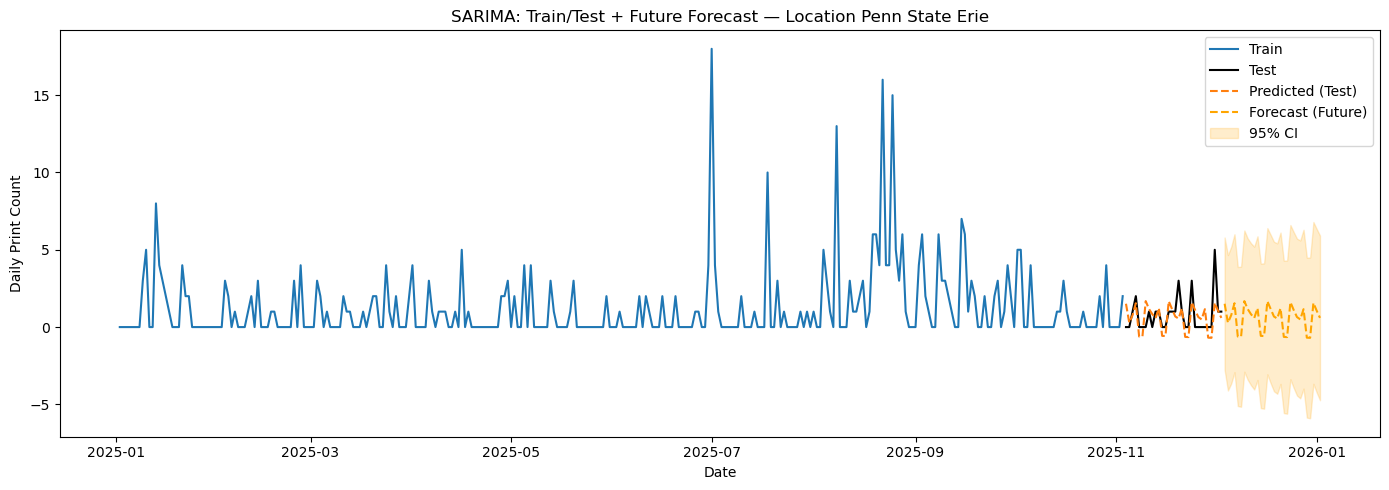

/home/trusted-service-user/cluster-env/clonedenv/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/home/trusted-service-user/cluster-env/clonedenv/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)



--- TEST SET ACCURACY ---
RMSE: 0.95
MAE:  0.71
MAPE: 42464019977.81%


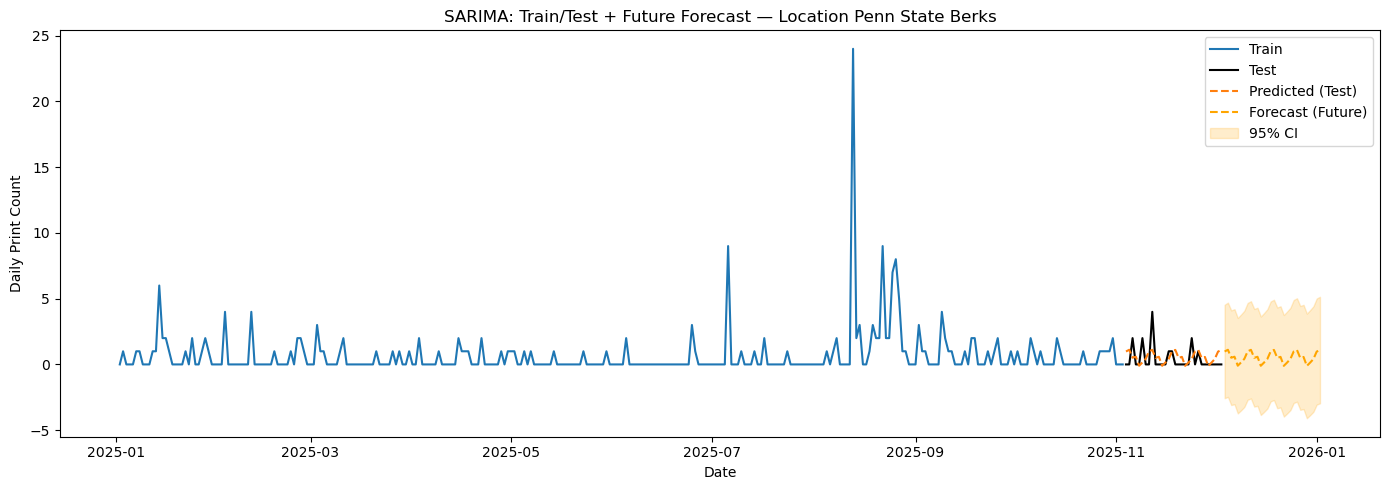

/home/trusted-service-user/cluster-env/clonedenv/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/home/trusted-service-user/cluster-env/clonedenv/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)



--- TEST SET ACCURACY ---
RMSE: 0.63
MAE:  0.50
MAPE: 29828235946.55%


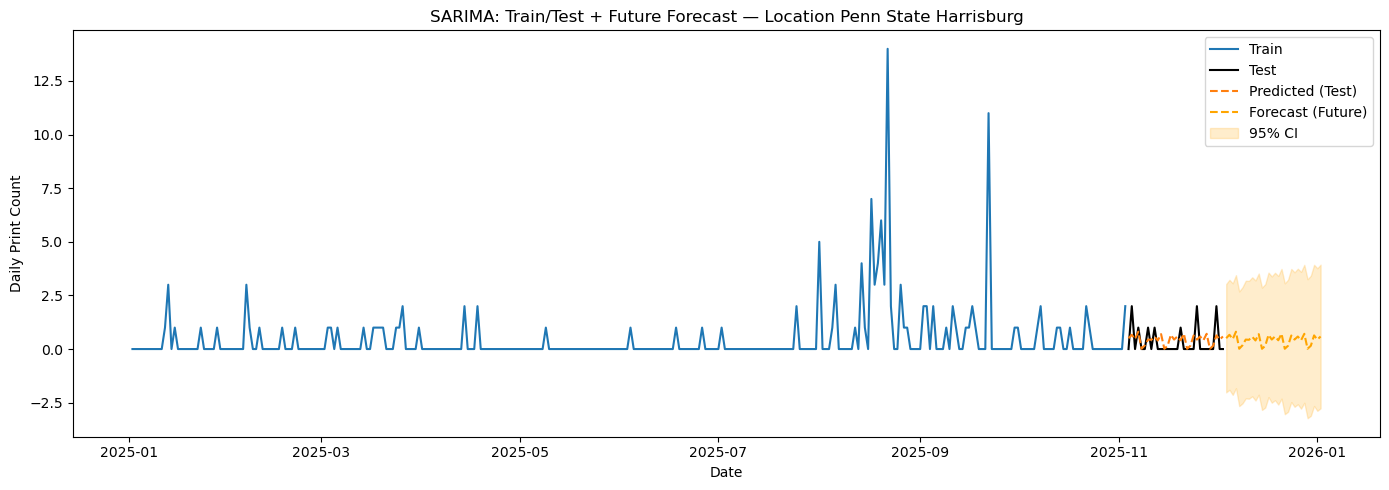

/home/trusted-service-user/cluster-env/clonedenv/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/home/trusted-service-user/cluster-env/clonedenv/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)



--- TEST SET ACCURACY ---
RMSE: 0.73
MAE:  0.48
MAPE: 18148114390.18%


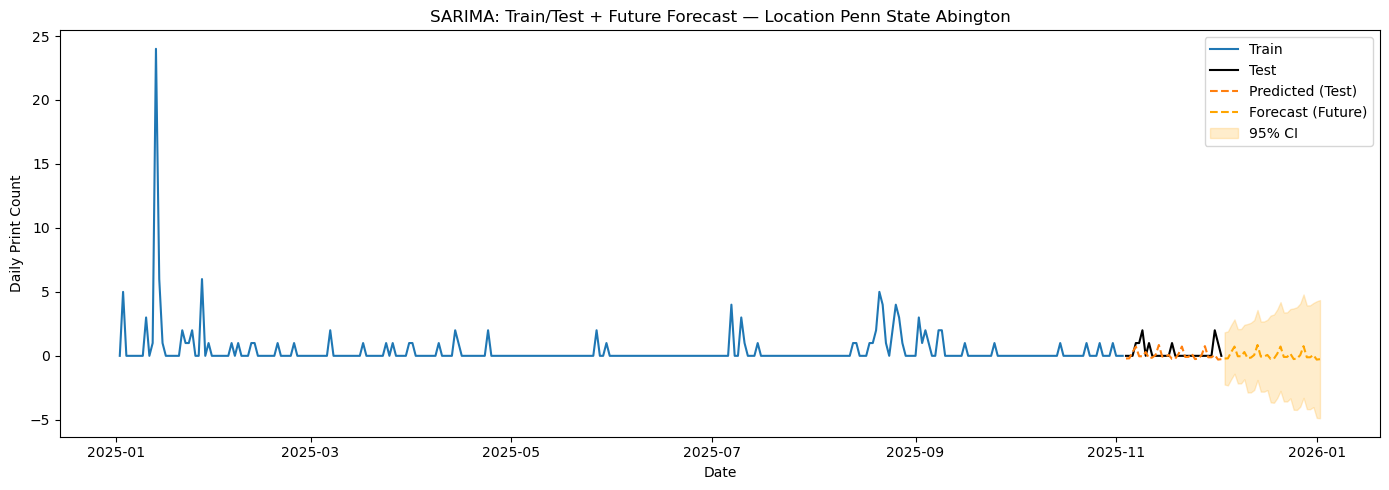

In [33]:
# ==========================================================
# TIME-SERIES FORECASTING WITH RMSE: OVERALL, REGIONS, DESCRIP
# ==========================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error, mean_absolute_error

plt.rcParams["figure.figsize"] = (14, 5)

# ----------------------------------------------------------
# 1. Rebuild FULL daily calendar with zeros per RegionGroup
# ----------------------------------------------------------
daily_region_raw = (
    pdf.groupby(["LOGDATE", "RegionGroup"])
       .size()
       .reset_index(name="PrintCount")
)

# Full date range across entire dataset
full_dates = pd.DataFrame({
    "LOGDATE": pd.date_range(
        start=daily_region_raw["LOGDATE"].min(),
        end=daily_region_raw["LOGDATE"].max(),
        freq="D"
    )
})

regions = sorted(daily_region_raw["RegionGroup"].unique())

# Full region × date grid
full_grid = (
    full_dates.assign(key=1)
    .merge(pd.DataFrame({"RegionGroup": regions, "key": 1}), on="key")
    .drop(columns="key")
)

# Merge observed counts, fill missing with 0
daily_region = (
    full_grid.merge(daily_region_raw,
                    on=["LOGDATE", "RegionGroup"],
                    how="left")
)
daily_region["PrintCount"] = daily_region["PrintCount"].fillna(0)
daily_region = daily_region.sort_values(["RegionGroup", "LOGDATE"])

print("Regions:", regions)
print("Overall date range:", daily_region["LOGDATE"].min(), "→", daily_region["LOGDATE"].max())

# ----------------------------------------------------------
# 2. Build overall daily series (all regions combined)
# ----------------------------------------------------------
daily_total = (
    daily_region.groupby("LOGDATE")["PrintCount"]
                .sum()
                .reset_index()
                .sort_values("LOGDATE")
)
ts_all = daily_total.set_index("LOGDATE")["PrintCount"]

# ----------------------------------------------------------
# 3. Build daily series per region
# ----------------------------------------------------------
ts_regions = {}
for reg in regions:
    sub = daily_region[daily_region["RegionGroup"] == reg]
    ts_regions[reg] = sub.set_index("LOGDATE")["PrintCount"]

# ----------------------------------------------------------
# 4. Build daily DESCRIP series with zeros, choose top 5
# ----------------------------------------------------------
daily_desc_raw = (
    pdf.groupby(["LOGDATE", "DESCRIP"])
       .size()
       .reset_index(name="PrintCount")
)

locations = sorted(daily_desc_raw["DESCRIP"].unique())

grid_desc = (
    full_dates.assign(key=1)
    .merge(pd.DataFrame({"DESCRIP": locations, "key": 1}), on="key")
    .drop(columns="key")
)

daily_desc = (
    grid_desc.merge(daily_desc_raw, on=["LOGDATE", "DESCRIP"], how="left")
)
daily_desc["PrintCount"] = daily_desc["PrintCount"].fillna(0)
daily_desc = daily_desc.sort_values(["DESCRIP", "LOGDATE"])

# Total volume per DESCRIP to pick top locations
desc_totals = (
    daily_desc.groupby("DESCRIP")["PrintCount"]
              .sum()
              .sort_values(ascending=False)
)

top_n = 5
top_locations = desc_totals.head(top_n).index.tolist()
print(f"\nTop {top_n} DESCRIP locations by total prints:")
print(desc_totals.head(top_n))

ts_desc = {}
for loc in top_locations:
    sub = daily_desc[daily_desc["DESCRIP"] == loc]
    ts_desc[loc] = sub.set_index("LOGDATE")["PrintCount"]

# ----------------------------------------------------------
# 5. Helper: Fit SARIMA WITH RMSE diagnostics + train/test split
# ----------------------------------------------------------
def fit_and_forecast(ts, label="", steps=30, 
                     order=(1,1,1), seasonal_order=(1,1,1,7),
                     test_size=30):
    """
    Fit SARIMA to a daily series, evaluate RMSE/MAE/MAPE on a test window,
    plot train/test/forecast, and return diagnostics.
    """

    print(f"\n===== TRAIN/TEST SARIMA FOR {label} =====")

    # --- Train/Test Split ---
    train = ts.iloc[:-test_size]
    test  = ts.iloc[-test_size:]

    # --- Fit SARIMA ---
    model = SARIMAX(
        train,
        order=order,
        seasonal_order=seasonal_order,
        enforce_stationarity=False,
        enforce_invertibility=False
    )
    results = model.fit(disp=False)
    
    # --- Forecast on test window ---
    fc_test = results.get_forecast(steps=test_size).predicted_mean
    fc_test.index = test.index  # ensure alignment

    # --- Compute error metrics ---
    rmse = np.sqrt(mean_squared_error(test, fc_test))
    mae  = mean_absolute_error(test, fc_test)
    mape = np.mean(np.abs((test - fc_test) / (test + 1e-9))) * 100

    print("\n--- TEST SET ACCURACY ---")
    print(f"RMSE: {rmse:.2f}")
    print(f"MAE:  {mae:.2f}")
    print(f"MAPE: {mape:.2f}%")

    # --- Now forecast FUTURE values ---
    future_forecast = results.get_forecast(steps=steps)
    fc_future_mean = future_forecast.predicted_mean
    fc_future_ci = future_forecast.conf_int()

    last_date = ts.index.max()
    fc_future_index = pd.date_range(start=last_date + pd.Timedelta(days=1),
                                    periods=steps, freq="D")
    fc_future_ci.index = fc_future_index

    # --- Plot ---
    plt.figure(figsize=(14,5))
    plt.plot(train.index, train, label="Train")
    plt.plot(test.index, test, label="Test", color="black")
    plt.plot(fc_test.index, fc_test, label="Predicted (Test)", linestyle="--")
    plt.plot(fc_future_index, fc_future_mean.values, label="Forecast (Future)", linestyle="--", color="orange")

    plt.fill_between(
        fc_future_index,
        fc_future_ci.iloc[:, 0].values,
        fc_future_ci.iloc[:, 1].values,
        alpha=0.2,
        color="orange",
        label="95% CI"
    )

    plt.title(f"SARIMA: Train/Test + Future Forecast — {label}")
    plt.xlabel("Date")
    plt.ylabel("Daily Print Count")
    plt.legend()
    plt.tight_layout()
    plt.show()

    return {
        "model": results,
        "rmse": rmse,
        "mae": mae,
        "mape": mape,
        "forecast_mean": fc_future_mean,
        "forecast_ci": fc_future_ci
    }

# ----------------------------------------------------------
# 6. Overall time-series forecast (all regions combined)
# ----------------------------------------------------------
diag_all = fit_and_forecast(
    ts_all,
    label="All Regions (Combined)",
    steps=30,
    test_size=30
)

# ----------------------------------------------------------
# 7. Regional time-series forecasts (UP, CWC, etc.)
# ----------------------------------------------------------
regional_diags = {}
for reg, ts in ts_regions.items():
    regional_diags[reg] = fit_and_forecast(
        ts,
        label=f"Region {reg}",
        steps=30,
        test_size=30
    )

# ----------------------------------------------------------
# 8. DESCRIP-level forecasts for top locations
# ----------------------------------------------------------
desc_diags = {}
for loc, ts in ts_desc.items():
    desc_diags[loc] = fit_and_forecast(
        ts,
        label=f"Location {loc}",
        steps=30,
        test_size=30
    )


StatementMeta(, 64169b29-2ac5-4013-bd3c-530b109c9137, 38, Finished, Available, Finished)


===== Decomposing series: All Regions (Combined) =====


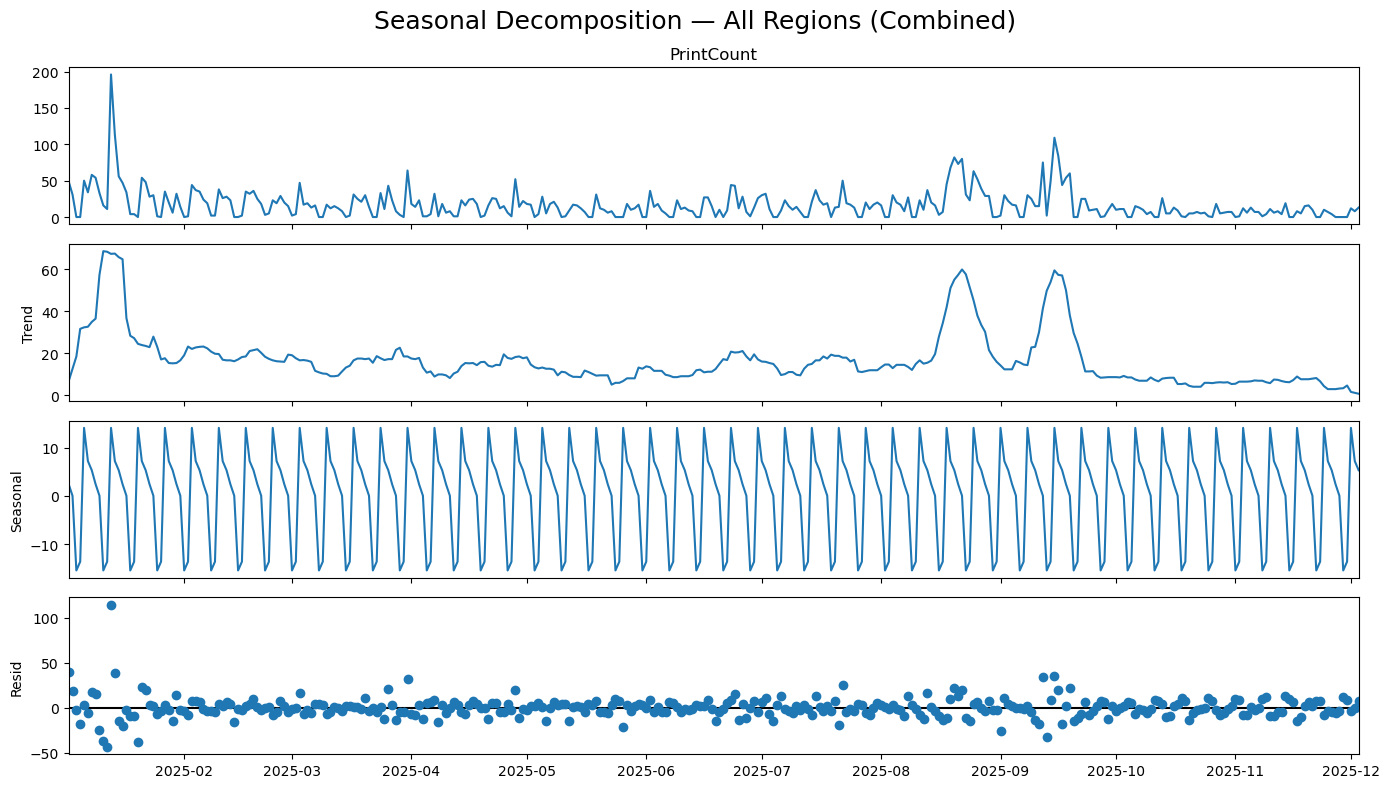


===== Decomposing series: Region CWC =====


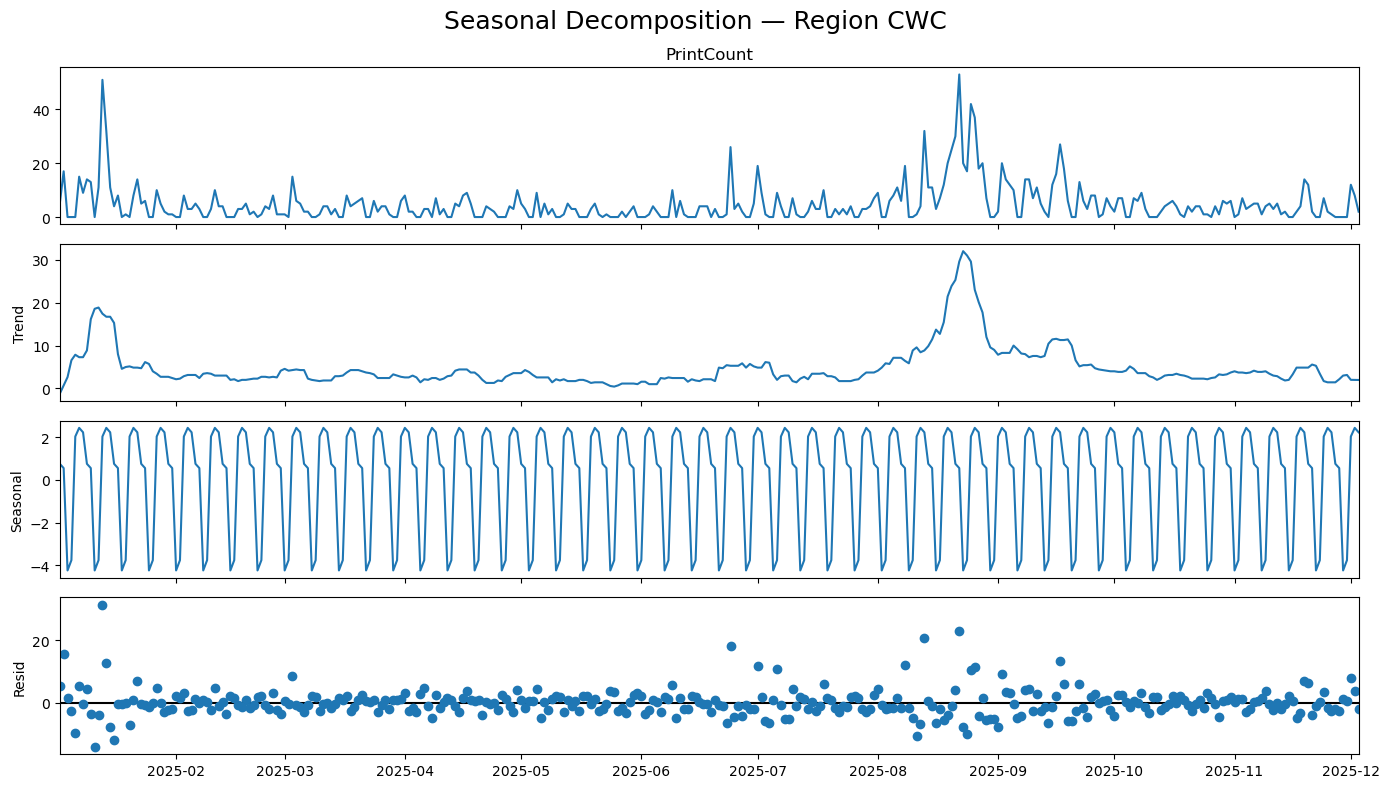


===== Decomposing series: Region UP =====


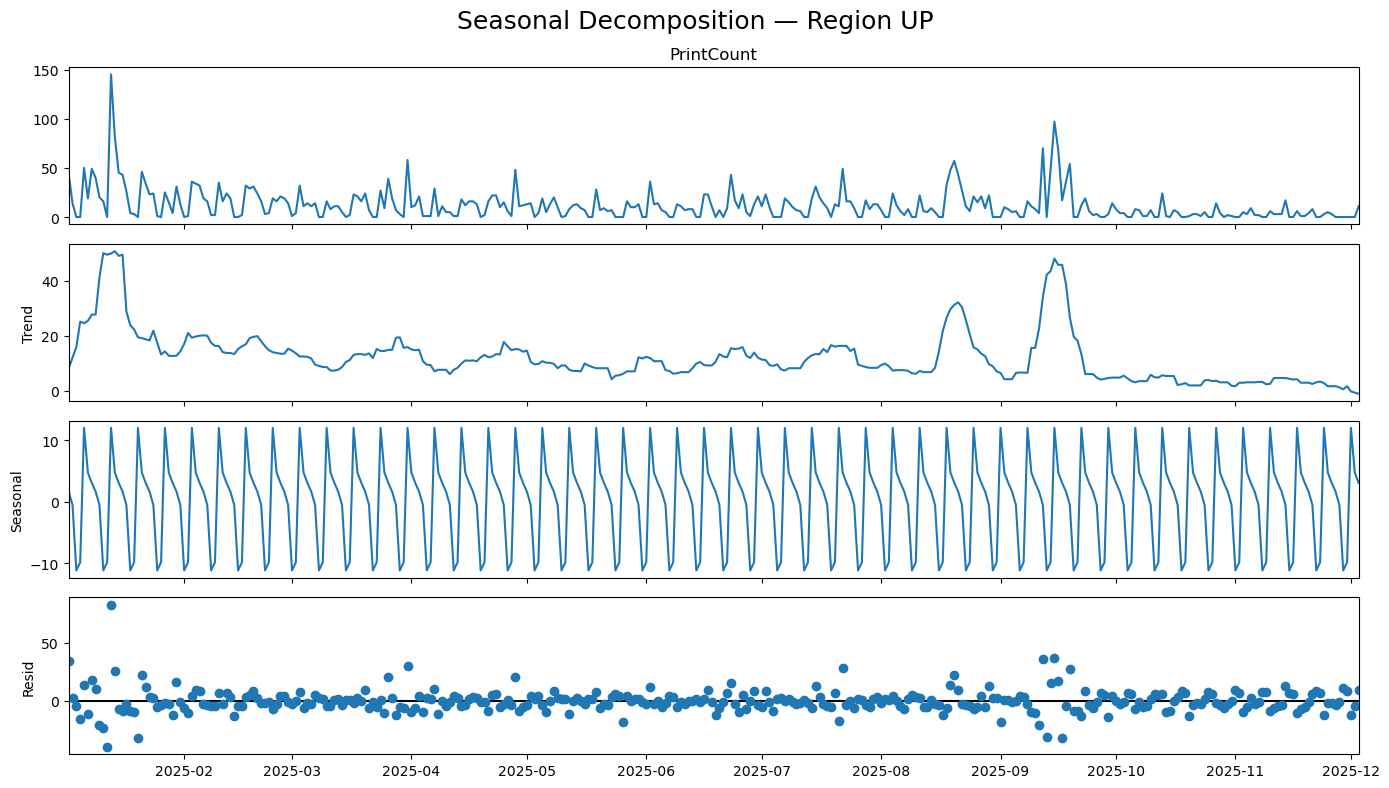

In [34]:
# ==========================================================
# SEASONAL DECOMPOSITION: OVERALL + REGIONGROUP
# ==========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

plt.rcParams["figure.figsize"] = (14, 5)

# ----------------------------------------------------------
# 1. Build region-level full calendar (fixed version)
# ----------------------------------------------------------
daily_region_raw = (
    pdf.groupby(["LOGDATE", "RegionGroup"])
       .size()
       .reset_index(name="PrintCount")
)

# Full date range
full_dates = pd.DataFrame({
    "LOGDATE": pd.date_range(
        start=daily_region_raw["LOGDATE"].min(),
        end=daily_region_raw["LOGDATE"].max(),
        freq="D"
    )
})

regions = sorted(daily_region_raw["RegionGroup"].unique())

# Full grid
full_grid = (
    full_dates.assign(key=1)
    .merge(pd.DataFrame({"RegionGroup": regions, "key": 1}), on="key")
    .drop(columns="key")
)

# Merge & fill zeros
daily_region = (
    full_grid.merge(daily_region_raw,
                    on=["LOGDATE", "RegionGroup"],
                    how="left")
)
daily_region["PrintCount"] = daily_region["PrintCount"].fillna(0)
daily_region = daily_region.sort_values(["RegionGroup", "LOGDATE"])

# ----------------------------------------------------------
# 2. Build overall series (sum of all regions)
# ----------------------------------------------------------
daily_total = (
    daily_region.groupby("LOGDATE")["PrintCount"]
                .sum()
                .reset_index()
)

ts_all = daily_total.set_index("LOGDATE")["PrintCount"]

# ----------------------------------------------------------
# 3. Build region-level series (UP, CWC)
# ----------------------------------------------------------
ts_regions = {}
for reg in regions:
    sub = daily_region[daily_region["RegionGroup"] == reg]
    ts_regions[reg] = sub.set_index("LOGDATE")["PrintCount"]

# ----------------------------------------------------------
# 4. Seasonal decomposition function (weekly seasonality=7)
# ----------------------------------------------------------
def decompose_and_plot(ts, title, period=7):
    """
    Perform STL/seasonal_decompose and plot components:
    Observed, Trend, Seasonal, Residual.
    """
    print(f"\n===== Decomposing series: {title} =====")
    result = seasonal_decompose(ts, model="additive", period=period, extrapolate_trend="freq")

    fig = result.plot()
    fig.set_size_inches(14, 8)
    fig.suptitle(f"Seasonal Decomposition — {title}", fontsize=18)
    plt.tight_layout()
    plt.show()

    return result

# ----------------------------------------------------------
# 5. Decompose OVERALL series
# ----------------------------------------------------------
result_all = decompose_and_plot(ts_all, title="All Regions (Combined)")

# ----------------------------------------------------------
# 6. Decompose EACH region
# ----------------------------------------------------------
region_decompositions = {}
for reg, ts in ts_regions.items():
    region_decompositions[reg] = decompose_and_plot(ts, title=f"Region {reg}")


StatementMeta(, 64169b29-2ac5-4013-bd3c-530b109c9137, 39, Finished, Available, Finished)

/tmp/ipykernel_10457/4258316727.py:22: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  overall_dow.groupby("Weekday")["PrintCount"]


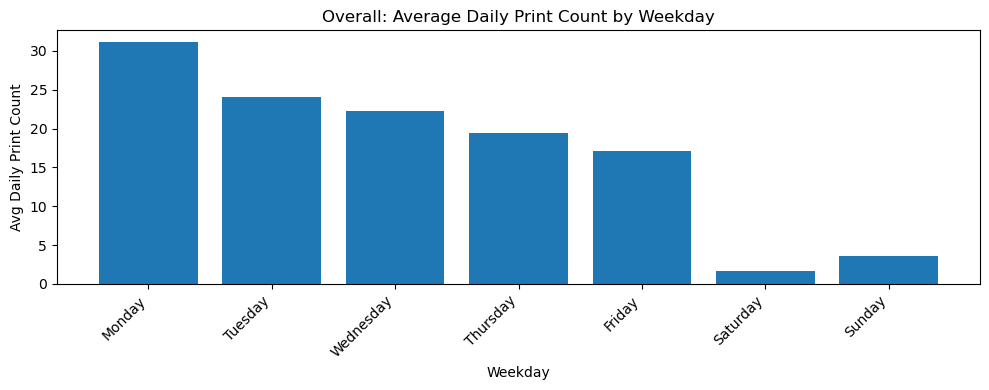


===== REGIONS: Average Daily Prints by Weekday =====
   RegionGroup    Weekday       mean     sum  count
0          CWC     Monday   6.895833   331.0     48
1          CWC    Tuesday   7.250000   348.0     48
2          CWC  Wednesday   7.041667   338.0     48
3          CWC   Thursday   5.500000   264.0     48
4          CWC     Friday   5.375000   258.0     48
5          CWC   Saturday   0.604167    29.0     48
6          CWC     Sunday   1.145833    55.0     48
7           UP     Monday  24.187500  1161.0     48
8           UP    Tuesday  16.854167   809.0     48
9           UP  Wednesday  15.166667   728.0     48
10          UP   Thursday  13.937500   669.0     48
11          UP     Friday  11.687500   561.0     48
12          UP   Saturday   1.041667    50.0     48
13          UP     Sunday   2.458333   118.0     48


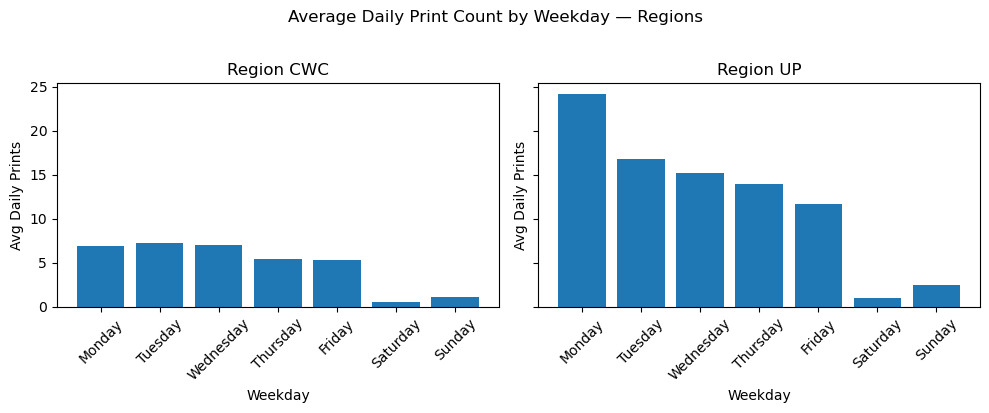


===== TOP LOCATIONS: Average Daily Prints by Weekday =====
                  DESCRIP    Weekday       mean     sum  count
0     Penn State Abington     Monday   1.000000    48.0     48
1     Penn State Abington    Tuesday   0.583333    28.0     48
2     Penn State Abington  Wednesday   0.333333    16.0     48
3     Penn State Abington   Thursday   0.354167    17.0     48
4     Penn State Abington     Friday   0.458333    22.0     48
5     Penn State Abington   Saturday   0.041667     2.0     48
6     Penn State Abington     Sunday   0.062500     3.0     48
7        Penn State Berks     Monday   0.583333    28.0     48
8        Penn State Berks    Tuesday   1.041667    50.0     48
9        Penn State Berks  Wednesday   1.229167    59.0     48
10       Penn State Berks   Thursday   0.625000    30.0     48
11       Penn State Berks     Friday   0.666667    32.0     48
12       Penn State Berks   Saturday   0.041667     2.0     48
13       Penn State Berks     Sunday   0.312500    15.0   

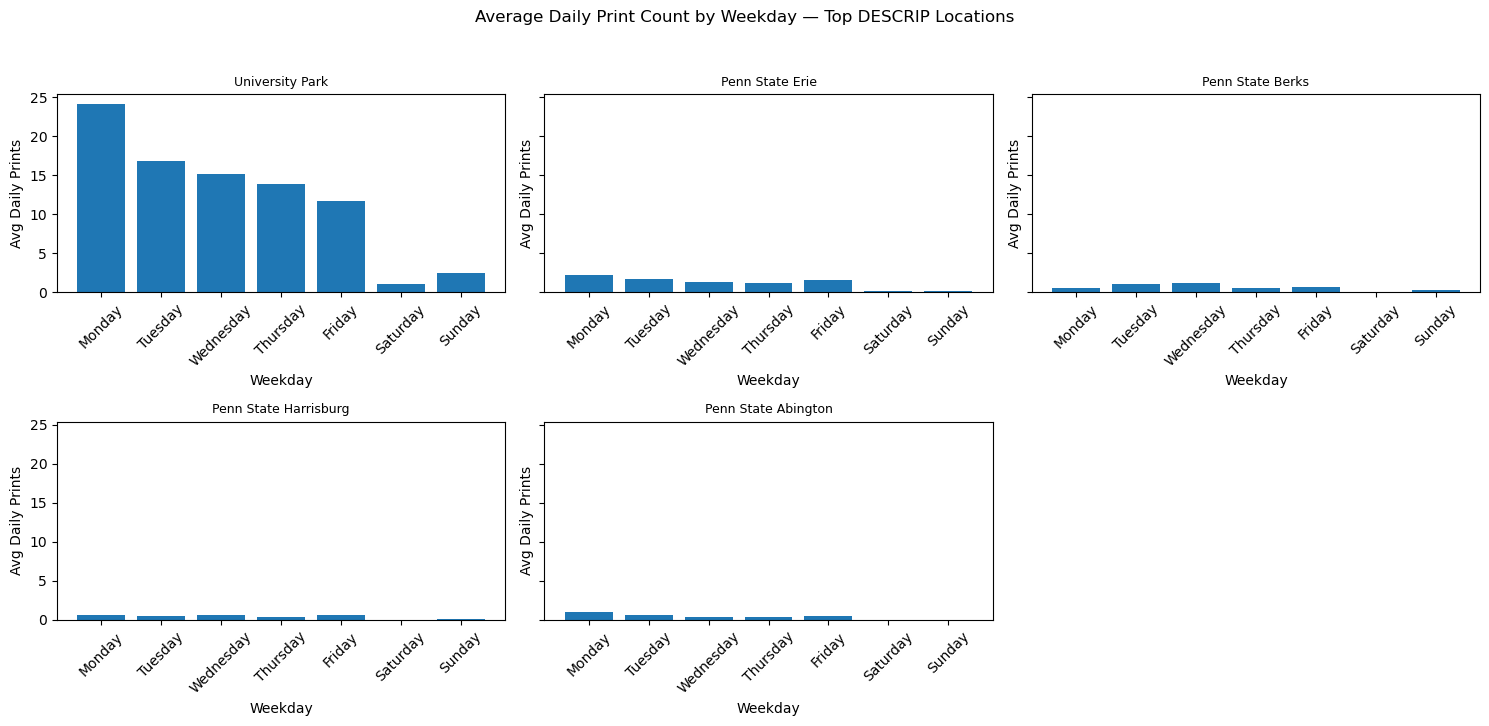

In [35]:
# ==========================================================
# DAY-OF-WEEK DISTRIBUTIONS: OVERALL, REGIONS, LOCATIONS
# ==========================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (14, 4)

weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

# ----------------------------------------------------------
# 1. OVERALL
# ----------------------------------------------------------
overall_dow = daily_total.copy()
overall_dow["Weekday"] = overall_dow["LOGDATE"].dt.day_name()
overall_dow["Weekday"] = pd.Categorical(overall_dow["Weekday"],
                                        categories=weekday_order,
                                        ordered=True)

overall_dow_stats = (
    overall_dow.groupby("Weekday")["PrintCount"]
               .agg(['mean', 'sum', 'count'])
               .reset_index()
)

print("\n===== OVERALL: Average Daily Prints by Weekday =====")
print(overall_dow_stats)

plt.figure(figsize=(10,4))
plt.bar(overall_dow_stats["Weekday"], overall_dow_stats["mean"])
plt.title("Overall: Average Daily Print Count by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Avg Daily Print Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# 2. REGIONS
# ----------------------------------------------------------
region_dow = daily_region.copy()
region_dow["Weekday"] = region_dow["LOGDATE"].dt.day_name()
region_dow["Weekday"] = pd.Categorical(region_dow["Weekday"],
                                       categories=weekday_order,
                                       ordered=True)

region_dow_stats = (
    region_dow.groupby(["RegionGroup", "Weekday"])["PrintCount"]
              .agg(['mean', 'sum', 'count'])
              .reset_index()
)

print("\n===== REGIONS: Average Daily Prints by Weekday =====")
print(region_dow_stats)

fig, axes = plt.subplots(1, len(regions), figsize=(5*len(regions), 4), sharey=True)

# Ensure axes is iterable
if len(regions) == 1:
    axes = [axes]

for ax, reg in zip(axes, regions):
    sub = region_dow_stats[region_dow_stats["RegionGroup"] == reg]
    ax.bar(sub["Weekday"], sub["mean"])
    ax.set_title(f"Region {reg}")
    ax.set_xlabel("Weekday")
    ax.set_ylabel("Avg Daily Prints")
    ax.tick_params(axis="x", rotation=45)   # <-- FIXED

plt.suptitle("Average Daily Print Count by Weekday — Regions", y=1.02)
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# 3. TOP LOCATIONS (DESCRIP)
# ----------------------------------------------------------
loc_dow = daily_desc.copy()
loc_dow["Weekday"] = loc_dow["LOGDATE"].dt.day_name()
loc_dow["Weekday"] = pd.Categorical(loc_dow["Weekday"],
                                    categories=weekday_order,
                                    ordered=True)

loc_dow_top = loc_dow[loc_dow["DESCRIP"].isin(top_locations)]

loc_dow_stats = (
    loc_dow_top.groupby(["DESCRIP", "Weekday"])["PrintCount"]
               .agg(['mean', 'sum', 'count'])
               .reset_index()
)

print("\n===== TOP LOCATIONS: Average Daily Prints by Weekday =====")
print(loc_dow_stats)

n_locs = len(top_locations)
n_cols = min(3, n_locs)
n_rows = int(np.ceil(n_locs / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols, 3.5*n_rows), sharey=True)
axes = np.atleast_1d(axes).ravel()

for i, loc in enumerate(top_locations):
    ax = axes[i]
    sub = loc_dow_stats[loc_dow_stats["DESCRIP"] == loc]
    ax.bar(sub["Weekday"], sub["mean"])
    ax.set_title(loc, fontsize=9)
    ax.set_xlabel("Weekday")
    ax.set_ylabel("Avg Daily Prints")
    ax.tick_params(axis="x", rotation=45)

# Hide unused axes
for j in range(i+1, len(axes)):
    axes[j].axis("off")

plt.suptitle("Average Daily Print Count by Weekday — Top DESCRIP Locations", y=1.03)
plt.tight_layout()
plt.show()


StatementMeta(, 64169b29-2ac5-4013-bd3c-530b109c9137, 41, Finished, Available, Finished)


===== DAILY PRINT COUNT FREQUENCY DISTRIBUTION BY LOCATION =====


--- University Park ---
PrintCount
0.0      78
1.0      20
2.0      10
3.0      13
4.0      10
5.0      13
6.0      10
7.0      13
8.0      11
9.0      10
10.0      8
11.0     13
12.0      6
13.0     12
14.0      9
15.0      4
16.0     14
17.0      4
18.0      1
19.0     10
20.0      3
21.0      6
22.0      4
23.0      6
24.0      6
25.0      1
26.0      1
27.0      2
28.0      1
29.0      2
31.0      3
32.0      3
33.0      1
34.0      2
35.0      1
36.0      3
39.0      1
40.0      1
43.0      3
44.0      1
45.0      1
46.0      1
48.0      2
49.0      3
50.0      1
54.0      1
57.0      1
58.0      1
68.0      1
70.0      1
81.0      1
97.0      1
145.0     1
Name: count, dtype: int64

--- Penn State Erie ---
PrintCount
0.0     196
1.0      52
2.0      30
3.0      22
4.0      16
5.0       7
6.0       6
7.0       1
8.0       1
10.0      1
13.0      1
15.0      1
16.0      1
18.0      1
Name: count, dtype: int64

--- 

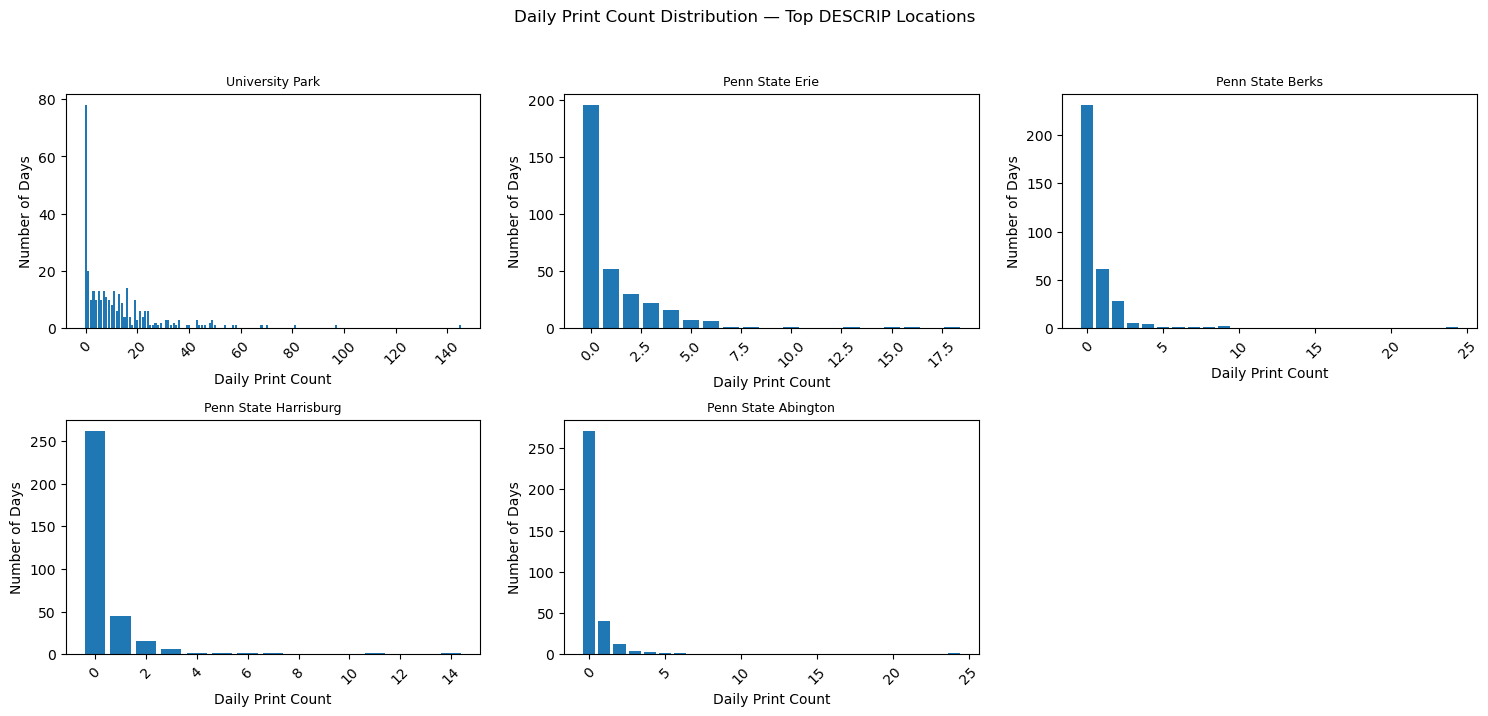

In [37]:
# ==========================================================
# DISTRIBUTION OF DAILY PRINT COUNTS (0, 1, 2, ...) BY LOCATION
# ==========================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (14, 4)

# daily_desc already exists and is zero-filled across entire date range
# top_locations already identified (top N busiest DESCRIPs)

print("\n===== DAILY PRINT COUNT FREQUENCY DISTRIBUTION BY LOCATION =====\n")

location_distributions = {}

for loc in top_locations:
    # Extract daily counts for this DESCRIP
    sub = daily_desc[daily_desc["DESCRIP"] == loc].copy()
    counts = sub["PrintCount"]

    # Frequency distribution: how many days had 0, 1, 2, ... prints
    freq = counts.value_counts().sort_index()

    location_distributions[loc] = freq

    print(f"\n--- {loc} ---")
    print(freq)

# ----------------------------------------------------------
# Plot histograms for each location (counts of daily volume)
# ----------------------------------------------------------

n_locs = len(top_locations)
n_cols = min(3, n_locs)
n_rows = int(np.ceil(n_locs / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols, 3.5*n_rows))

axes = np.atleast_1d(axes).ravel()

for i, loc in enumerate(top_locations):
    ax = axes[i]
    freq = location_distributions[loc]

    # Bar chart: x = daily print count, y = number of days at that count
    ax.bar(freq.index, freq.values)
    ax.set_title(loc, fontsize=9)
    ax.set_xlabel("Daily Print Count")
    ax.set_ylabel("Number of Days")
    ax.tick_params(axis="x", rotation=45)

# Hide any leftover subplots
for j in range(i+1, len(axes)):
    axes[j].axis("off")

plt.suptitle("Daily Print Count Distribution — Top DESCRIP Locations", y=1.03)
plt.tight_layout()
plt.show()
